# AH2179 Final Project — Short-Term Traffic Flow Prediction

### Main research question

> **Does incorporating spatial information from other traffic sensors improve short-term flow prediction compared with using only the target sensor's historical flow?**

### Research questions

1. **Baseline:** How accurately can future 15-minute traffic flow be predicted using only the target sensor's historical flow?

2. **Spatial information:** Does incorporating information from other traffic sensors improve 15-minute flow prediction compared with using only the target sensor's historical flow?

3. **Spatial extent:** How does prediction accuracy change as information from an increasing spatial range of sensors is incorporated?

4. **Spatial variation:** Does the effect of spatial information on prediction accuracy vary between sensors and portals?

### Important: flow-only prediction


structure of the notebook:

2021 training data → minute-grid features → chronological development and validation periods

Baseline analysis: Linear Regression with A–E (descriptive comparison only)

Joint search: each algorithm × A–E × parameter candidates → expanding chronological CV

Best configuration + parameters for each algorithm → common validation comparison

Refit the winning combination on 2021 → final 2022 benchmark → save model and results

## 1. Import libraries

In [1260]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.model_selection import ParameterSampler
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
# Shared reproducible training subset for all algorithms, including kernel SVR.
# Set to None to train on every eligible 2021 row (SVR can be expensive).
MAX_TRAIN_ROWS = 6000
MAX_TUNING_ROWS = 6000
# Joint-search budget: raise these after an initial reproducible comparison.
N_CV_SPLITS = 3
SEARCH_ITERATIONS = 4
MAX_CV_TRAIN_ROWS = 3000
MAX_CV_VALIDATION_ROWS = 3000


#### Forecast-output settings


In [1261]:
# Choose model inputs and output before running the notebook.

HORIZON = 15                 # Choose 15, 30 or 60 minutes.
TARGET_MODE = "window"      # "window": future sum/mean; "point": FLOW at t+HORIZON.    # tested point mode, completely unworkable
TARGET_AGGREGATION = "sum"   # "sum" or "mean"; used only in window mode.
FLOW_LAGS = [1, 5, 15, 30, 60]  # tried add 2mins and 10 mins, performance didn't change much but best configuration and best model combination changed
FEATURE_VERSION = ''  # Separate these inputs from previously trained models, the name is appended to the model folder filename. Use '' for the default feature set.

if HORIZON not in (15, 30, 60):
    raise ValueError('HORIZON must be 15, 30 or 60 minutes.')
if TARGET_MODE not in ('window', 'point'):
    raise ValueError('TARGET_MODE must be "window" or "point".')
if TARGET_AGGREGATION not in ('sum', 'mean'):
    raise ValueError('TARGET_AGGREGATION must be "sum" or "mean".')

TARGET_KIND = TARGET_AGGREGATION if TARGET_MODE == 'window' else 'point'
TARGET_UNIT = 'vehicles' if TARGET_KIND == 'sum' else 'vehicles/min'
if TARGET_MODE == 'point':
    TARGET_DESCRIPTION = f'Observed one-minute FLOW at exactly t+{HORIZON} minutes'
    TARGET_AXIS_LABEL = f'FLOW at t+{HORIZON} (vehicles/min)'
    TARGET_SPECIFICATION = f'observed FLOW at exactly t+{HORIZON}; not a future-window aggregate'
else:
    TARGET_DESCRIPTION = f'Next {HORIZON}-minute {TARGET_AGGREGATION} of FLOW'
    TARGET_AXIS_LABEL = (f'Vehicles / next {HORIZON} min' if TARGET_AGGREGATION == 'sum'
                         else f'Mean vehicles/min over next {HORIZON} min')
    TARGET_SPECIFICATION = f'{TARGET_AGGREGATION} of observed FLOW at t+1 through t+{HORIZON}'
TARGET_PERSISTENCE_FACTOR = HORIZON if TARGET_KIND == 'sum' else 1
print('Model output:', TARGET_DESCRIPTION, '| Units:', TARGET_UNIT)
print('Historical FLOW lags:', FLOW_LAGS)


Model output: Next 15-minute sum of FLOW | Units: vehicles
Historical FLOW lags: [1, 5, 15, 30, 60]


## 2. Import data

In [1262]:
# Support execution from either the notebook directory or project/data directory.
data_candidates = [Path('../project/data/dataset_for_traffic_project_assignment'),
                   Path('data/dataset_for_traffic_project_assignment')]
DATA_DIR = next((p.resolve() for p in data_candidates
                 if (p / 'training_dataset.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Locate the private course dataset and update data_candidates.')
TRAIN_PATH = DATA_DIR / 'training_dataset.csv'
FINAL_EVAL_PATH = DATA_DIR / 'final_evaluation_dataset.csv'
EVAL_PATH = DATA_DIR / 'evaluation_dataset.csv'
# evaluation_dataset.csv is not used for development or model selection.
OUTPUT_DIR = Path.cwd() / 'model_results' / f'{HORIZON}min_{TARGET_KIND}' / FEATURE_VERSION
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [1263]:
# import traning data 
train_raw = pd.read_csv(
    TRAIN_PATH,
    sep=";"
)

print("Training data shape:", train_raw.shape)

display(train_raw.head())

Training data shape: (1921967, 11)


,DP_ID,PORTAL,Date,Time,Interval_1,Interval_5,Interval_15,Interval_30,Interval_60,SPEED_MS_AVG,FLOW
0,543,"E4S 56,780",20210601,04:00:00,240,48,16,8,4,19.34,10.0
1,539,"E4S 56,160",20210601,04:00:00,240,48,16,8,4,19.64,9.0
2,534,"E4S 56,780",20210601,04:00:00,240,48,16,8,4,23.36,5.0
3,351,"E4S 56,490",20210601,04:00:00,240,48,16,8,4,20.14,7.0
4,353,"E4S 57,055",20210601,04:00:00,240,48,16,8,4,17.70,7.0


### 2.1 Morning peak

In [1264]:
# Extract the peak using numeric minutes; retain full history in train.
train = train_raw.copy()
train['timestamp'] = pd.to_datetime(
    train['Date'].astype(str) + ' ' + train['Time'].astype(str), errors='coerce')
minute_of_day = train['timestamp'].dt.hour * 60 + train['timestamp'].dt.minute
morning_peak = train.loc[minute_of_day.between(450, 510)].copy()
print('Morning peak observations:', len(morning_peak))
display(morning_peak.head())

Morning peak observations: 347657


,DP_ID,PORTAL,Date,Time,Interval_1,Interval_5,Interval_15,Interval_30,Interval_60,SPEED_MS_AVG,FLOW,timestamp
5517,4872,"E4S 56,780",20210601,07:30:00,450,90,30,15,7,16.11,7.0,2021-06-01 07:30:00
5518,4873,"E4S 56,490",20210601,07:30:00,450,90,30,15,7,17.22,11.0,2021-06-01 07:30:00
5519,543,"E4S 56,780",20210601,07:30:00,450,90,30,15,7,15.69,20.0,2021-06-01 07:30:00
5520,539,"E4S 56,160",20210601,07:30:00,450,90,30,15,7,18.93,12.0,2021-06-01 07:30:00
5521,534,"E4S 56,780",20210601,07:30:00,450,90,30,15,7,19.46,14.0,2021-06-01 07:30:00


## 3. Data engineering

In [1265]:
# create timestamp

train["timestamp"] = pd.to_datetime(
    train["Date"].astype(str) + " " + train["Time"].astype(str),
    errors="coerce"
)

train["FLOW"] = pd.to_numeric(
    train["FLOW"],
    errors="coerce"
)

train["SPEED_MS_AVG"] = pd.to_numeric(
    train["SPEED_MS_AVG"],
    errors="coerce"
)

train = train.sort_values(
    ["DP_ID", "timestamp"]
).reset_index(drop=True)

print("Earliest observation:", train["timestamp"].min())
print("Latest observation:", train["timestamp"].max())

display(train.head())


Earliest observation: 2021-06-01 04:00:00
Latest observation: 2021-12-31 10:00:00


,DP_ID,PORTAL,Date,Time,Interval_1,Interval_5,Interval_15,Interval_30,Interval_60,SPEED_MS_AVG,FLOW,timestamp
0,153,"E4S 56,490",20210601,04:00:00,240,48,16,8,4,27.50,1.0,2021-06-01 04:00:00
1,153,"E4S 56,490",20210601,04:01:00,241,48,16,8,4,25.57,11.0,2021-06-01 04:01:00
2,153,"E4S 56,490",20210601,04:02:00,242,48,16,8,4,23.83,12.0,2021-06-01 04:02:00
3,153,"E4S 56,490",20210601,04:03:00,243,48,16,8,4,24.59,10.0,2021-06-01 04:03:00
4,153,"E4S 56,490",20210601,04:04:00,244,48,16,8,4,27.36,5.0,2021-06-01 04:04:00


In [1266]:
# check sensors and portal
number_sensors = train["DP_ID"].nunique()
number_portals = train["PORTAL"].nunique()

print("Number of sensors:", number_sensors)
print("Number of portals:", number_portals)

print("\nSensors per portal:")

sensors_per_portal = (
    train.groupby("PORTAL")["DP_ID"]
    .nunique()
    .sort_values()
)

display(sensors_per_portal)

Number of sensors: 29
Number of portals: 8

Sensors per portal:


PORTAL
E4S 55,620    3
E4S 56,160    3
E4S 57,055    3
E4S 57,435    3
E4S 56,490    4
E4S 56,780    4
E4S 57,820    4
E4S 58,140    5
Name: DP_ID, dtype: int64

In [1267]:
# sensor/portal table

sensor_portal = (
    train[["DP_ID", "PORTAL"]]
    .drop_duplicates()
    .sort_values(["PORTAL", "DP_ID"])
    .reset_index(drop=True)
)

display(sensor_portal)

,DP_ID,PORTAL
0,751,"E4S 55,620"
1,1076,"E4S 55,620"
2,1254,"E4S 55,620"
3,536,"E4S 56,160"
4,539,"E4S 56,160"
5,740,"E4S 56,160"
6,153,"E4S 56,490"
7,351,"E4S 56,490"
8,902,"E4S 56,490"
9,4873,"E4S 56,490"


### 3.1 Missing values

In [1268]:
# train = train_raw.copy()

print("Missing FLOW:", train["FLOW"].isna().sum())
print("Missing SPEED:", train["SPEED_MS_AVG"].isna().sum())
print("Negative FLOW:", (train["FLOW"] < 0).sum())
print("Zero FLOW:", (train["FLOW"] == 0).sum())
print("Duplicate sensor-minute rows:",
      train.duplicated(["DP_ID", "timestamp"]).sum())

display(train.groupby("PORTAL")["FLOW"].agg(["count", "mean", "median", "std"]))
# train = train_raw.copy()


Missing FLOW: 62
Missing SPEED: 0
Negative FLOW: 0
Zero FLOW: 0
Duplicate sensor-minute rows: 0


,count,mean,median,std
PORTAL,,,,
"E4S 55,620",217095,14.979046,16.0,7.033610
"E4S 56,160",217055,15.094386,15.0,7.390930
"E4S 56,490",263024,12.445378,12.0,7.552004
"E4S 56,780",272954,12.367560,13.0,7.835594
"E4S 57,055",218102,15.844032,17.0,7.646034
"E4S 57,435",200755,11.955085,11.0,8.296019
"E4S 57,820",239221,9.783196,7.0,8.027942
"E4S 58,140",293699,8.144226,5.0,7.092720


In [1269]:
# Remove rows where FLOW is missing.
# Zero FLOW values are retained.

train = train.dropna(
    subset=["FLOW"]
).copy()

print("Rows after removing missing FLOW:", len(train))
print("Remaining missing FLOW:", train["FLOW"].isna().sum())

Rows after removing missing FLOW: 1921905
Remaining missing FLOW: 0


## 4. Exploratory Data Analysis

### 4.1 Flow distribution

In [1270]:
sensor_statistics = (
    train.groupby("DP_ID")["FLOW"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .sort_values("mean", ascending=False)
)

display(sensor_statistics)

,count,mean,median,std,min,max
DP_ID,,,,,,
740,74047,19.139047,21.0,7.083077,1.0,37.0
749,73984,19.015990,21.0,7.185573,1.0,39.0
751,74201,17.740933,19.0,6.594491,1.0,36.0
1079,73938,16.912481,18.0,6.592638,1.0,36.0
902,73933,16.554705,18.0,7.077330,1.0,37.0
543,73756,15.133467,16.0,6.807797,1.0,35.0
353,72983,14.821671,16.0,6.988171,1.0,36.0
1076,73954,14.651378,16.0,6.386678,1.0,41.0
4430,65869,14.094263,15.0,8.642839,1.0,38.0


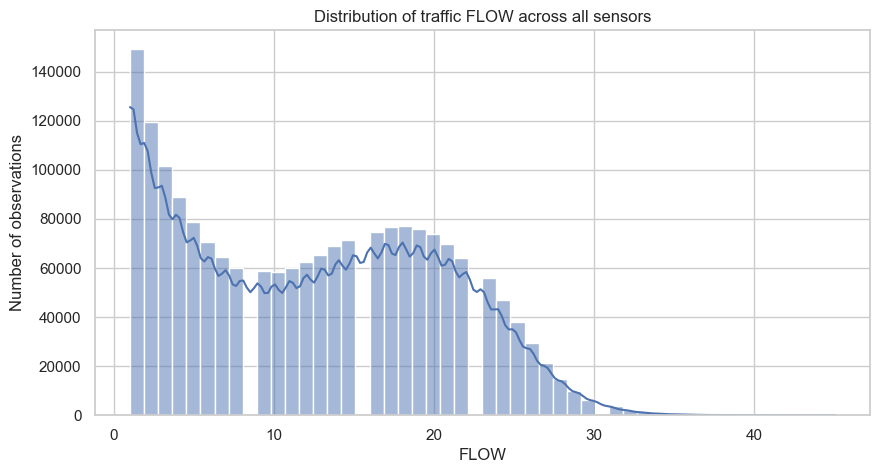

In [1271]:
# flow distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    train["FLOW"].dropna(),
    bins=50,
    kde=True
)

plt.xlabel("FLOW")
plt.ylabel("Number of observations")
plt.title("Distribution of traffic FLOW across all sensors")
plt.show()

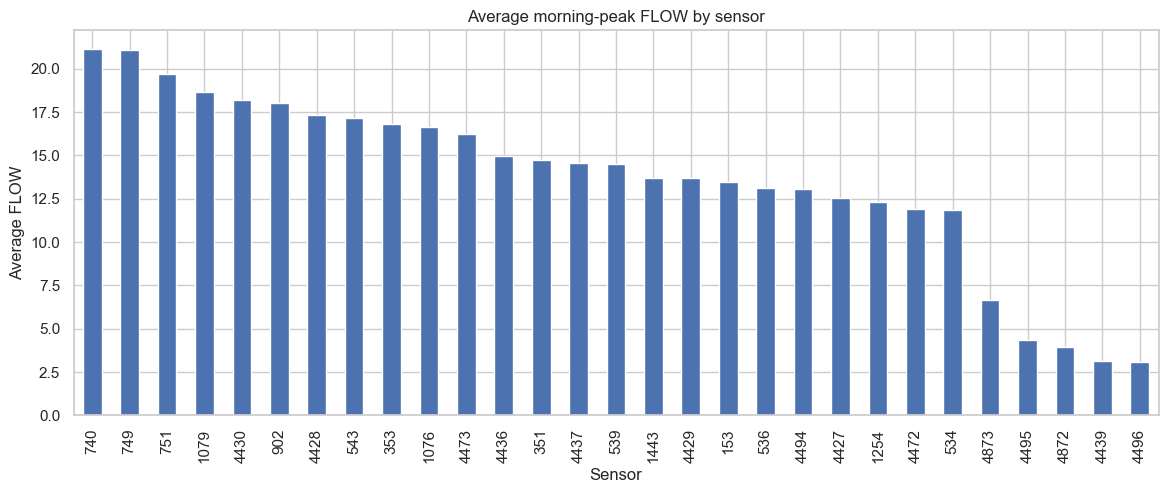

In [1272]:
# morning av flow

morning_sensor_flow = (
    morning_peak.groupby("DP_ID")["FLOW"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 5))

morning_sensor_flow.plot(
    kind="bar"
)

plt.xlabel("Sensor")
plt.ylabel("Average FLOW")
plt.title("Average morning-peak FLOW by sensor")
plt.xticks(rotation=90)
plt.show()

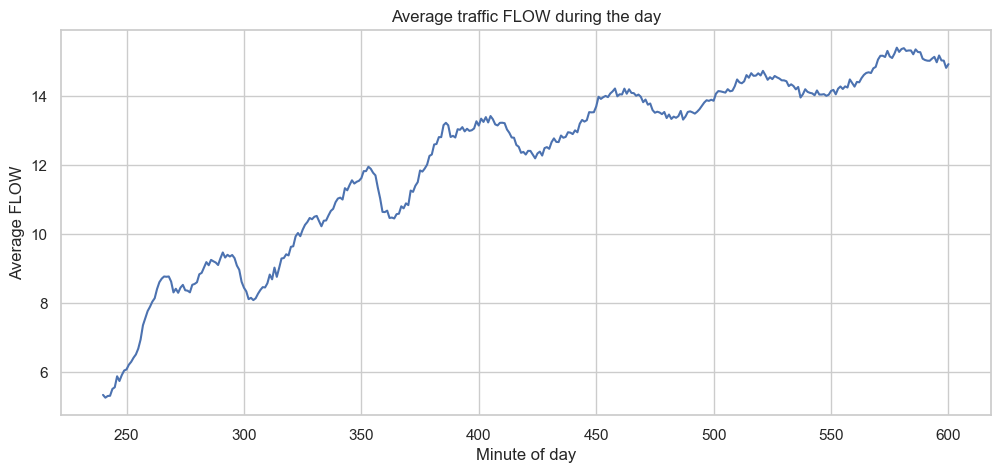

In [1273]:
# daily flow

train["minute_of_day"] = (
    train["timestamp"].dt.hour * 60
    + train["timestamp"].dt.minute
)

daily_flow = (
    train.groupby("minute_of_day")["FLOW"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_flow.index,
    daily_flow.values
)

plt.xlabel("Minute of day")
plt.ylabel("Average FLOW")
plt.title("Average traffic FLOW during the day")
plt.show()

### 4.2 Speed-flow relationship

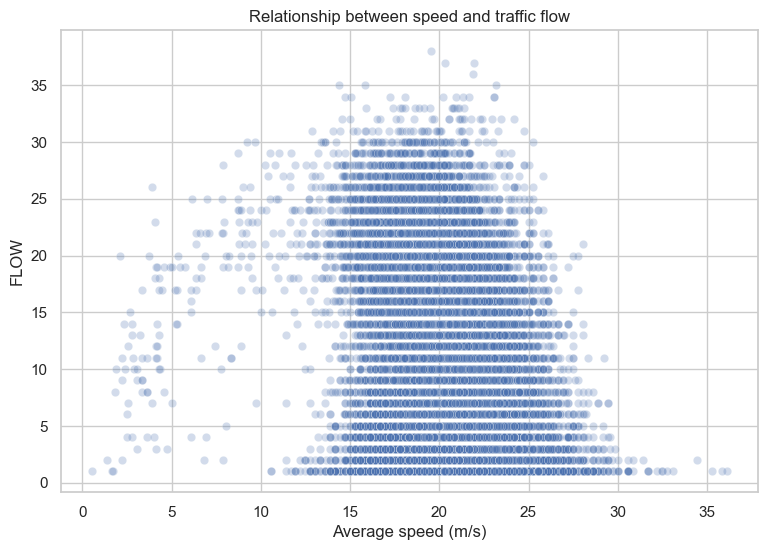

In [1274]:
sample = train.dropna(
    subset=["FLOW", "SPEED_MS_AVG"]
).sample(
    min(20000, train.dropna(
        subset=["FLOW", "SPEED_MS_AVG"]
    ).shape[0]),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample,
    x="SPEED_MS_AVG",
    y="FLOW",
    alpha=0.25
)

plt.xlabel("Average speed (m/s)")
plt.ylabel("FLOW")
plt.title("Relationship between speed and traffic flow")
plt.show()

### 4.3 Sensor correlation

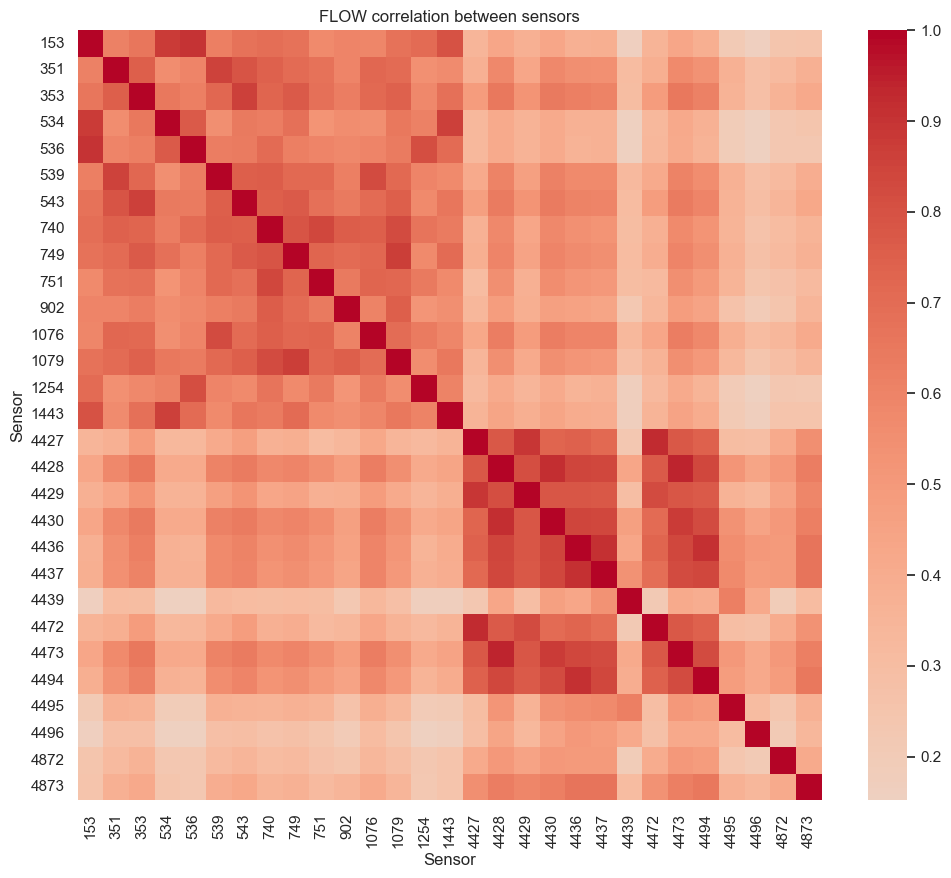

In [1275]:
sensor_flow_wide = (
    train.pivot_table(
        index="timestamp",
        columns="DP_ID",
        values="FLOW",
        aggfunc="mean"
    )
)

sensor_correlation = sensor_flow_wide.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    sensor_correlation,
    cmap="coolwarm",
    center=0
)

plt.title("FLOW correlation between sensors")
plt.xlabel("Sensor")
plt.ylabel("Sensor")
plt.show()

## 5. Model Development - Prediction

### 5.1 Check the 1-minute time structure

Important to check whether the df contains observations at approximately 1-minute intervals:
- how often timestamps occur
- whether there are gaps
- whether different sensors have different amounts of missing tim

In [1276]:
# Calculate the time difference between consecutive observations for each sensor.

time_gaps = (
    train.sort_values(["DP_ID", "timestamp"])
    .groupby("DP_ID")["timestamp"]
    .diff()
)

print("Most common time differences:")

display(
    time_gaps.value_counts().head(10)
)

Most common time differences:


timestamp
0 days 00:01:00    1827205
0 days 00:02:00      53516
0 days 00:03:00      16035
0 days 00:04:00       7347
0 days 00:05:00       3939
0 days 18:00:00       3870
0 days 00:06:00       2532
0 days 00:07:00       1534
0 days 00:08:00       1001
0 days 00:09:00        632
Name: count, dtype: int64

In [1277]:
# Find gaps and show their duration.

previous_timestamp = train.groupby('DP_ID')['timestamp'].shift(1)
time_gaps = train['timestamp'] - previous_timestamp
large_gaps = train.loc[time_gaps > pd.Timedelta(minutes=1), ['DP_ID', 'timestamp']].copy()
large_gaps['previous_timestamp'] = previous_timestamp.loc[large_gaps.index]
large_gaps['time_gap'] = time_gaps.loc[large_gaps.index]
large_gaps['gap_minutes'] = large_gaps['time_gap'].dt.total_seconds() / 60
large_gaps['estimated_missing_minutes'] = large_gaps['gap_minutes'] - 1
large_gaps['crosses_date_boundary'] = (
    large_gaps['timestamp'].dt.normalize() != large_gaps['previous_timestamp'].dt.normalize()
)
print('Number of gaps larger than 1 minute:', len(large_gaps))
display(large_gaps.head(20))

Number of gaps larger than 1 minute: 94671


,DP_ID,timestamp,previous_timestamp,time_gap,gap_minutes,estimated_missing_minutes,crosses_date_boundary
361,153,2021-06-02 04:00:00,2021-06-01 10:00:00,0 days 18:00:00,1080.0,1079.0,True
722,153,2021-06-03 04:00:00,2021-06-02 10:00:00,0 days 18:00:00,1080.0,1079.0,True
1083,153,2021-06-04 04:00:00,2021-06-03 10:00:00,0 days 18:00:00,1080.0,1079.0,True
1444,153,2021-06-05 04:00:00,2021-06-04 10:00:00,0 days 18:00:00,1080.0,1079.0,True
1448,153,2021-06-05 04:05:00,2021-06-05 04:03:00,0 days 00:02:00,2.0,1.0,False
1454,153,2021-06-05 04:12:00,2021-06-05 04:10:00,0 days 00:02:00,2.0,1.0,False
1456,153,2021-06-05 04:15:00,2021-06-05 04:13:00,0 days 00:02:00,2.0,1.0,False
1465,153,2021-06-05 04:25:00,2021-06-05 04:23:00,0 days 00:02:00,2.0,1.0,False
1471,153,2021-06-05 04:32:00,2021-06-05 04:30:00,0 days 00:02:00,2.0,1.0,False
1478,153,2021-06-05 04:41:00,2021-06-05 04:38:00,0 days 00:03:00,3.0,2.0,False


#### Gap summary by sensor

In [1278]:
# Summarize the number and duration of gaps.

gaps_by_sensor = large_gaps.groupby('DP_ID').agg(
    number_of_large_gaps=('gap_minutes', 'size'),
    median_gap_minutes=('gap_minutes', 'median'),
    maximum_gap_minutes=('gap_minutes', 'max')
).sort_values('number_of_large_gaps', ascending=False).reset_index()
display(gaps_by_sensor)

,DP_ID,number_of_large_gaps,median_gap_minutes,maximum_gap_minutes
0,4496,11266,2.0,1315.0
1,4439,10582,2.0,1315.0
2,4872,9600,2.0,1315.0
3,4495,8181,2.0,1315.0
4,4873,7246,2.0,34203.0
5,4429,6312,2.0,1315.0
6,4472,6066,3.0,1315.0
7,4427,5910,3.0,1315.0
8,4437,3121,2.0,1315.0
9,1254,2760,2.0,2748.0


In [1279]:
within_day_gaps = large_gaps.loc[
    ~large_gaps["crosses_date_boundary"]
].copy()

within_day_gap_summary = (
    within_day_gaps
    .groupby("DP_ID")
    .agg(
        number_of_within_day_gaps=(
            "gap_minutes",
            "size"
        ),
        median_gap_minutes=(
            "gap_minutes",
            "median"
        ),
        mean_gap_minutes=(
            "gap_minutes",
            "mean"
        ),
        maximum_gap_minutes=(
            "gap_minutes",
            "max"
        ),
        total_missing_minutes=(
            "estimated_missing_minutes",
            "sum"
        )
    )
    .reset_index()
    .sort_values(
        "number_of_within_day_gaps",
        ascending=False
    )
)

display(within_day_gap_summary)

,DP_ID,number_of_within_day_gaps,median_gap_minutes,mean_gap_minutes,maximum_gap_minutes,total_missing_minutes
26,4496,11053,2.0,3.420700,266.0,26756.0
21,4439,10369,2.0,3.087954,263.0,21650.0
27,4872,9387,2.0,3.136678,267.0,20057.0
25,4495,7968,2.0,2.947415,264.0,15517.0
28,4873,7056,2.0,3.030612,264.0,14328.0
17,4429,6099,2.0,3.255616,263.0,13757.0
22,4472,5853,3.0,3.762515,265.0,16169.0
15,4427,5697,3.0,4.005441,265.0,17122.0
20,4437,2908,2.0,2.428129,263.0,4153.0
13,1254,2550,2.0,3.039216,122.0,5200.0


#### Check whether FLOW contains zeros

In [1280]:
# Calculate the percentage of zero FLOW observations for each sensor.

zero_summary = (
    train.groupby("DP_ID")["FLOW"]
    .agg(
        total_observations="count",
        zero_observations=lambda x: (x == 0).sum()
    )
)

zero_summary["zero_percent"] = (
    zero_summary["zero_observations"]
    / zero_summary["total_observations"]
    * 100
)

display(
    zero_summary.sort_values(
        "zero_percent",
        ascending=False
    )
)

,total_observations,zero_observations,zero_percent
DP_ID,,,
153,70069,0,0.0
4427,57798,0,0.0
4872,56048,0,0.0
4496,49149,0,0.0
4495,60955,0,0.0
4494,50591,0,0.0
4473,74447,0,0.0
4472,58557,0,0.0
4439,54773,0,0.0


### 5.2 Prediction setup: rolling prediction


In [1281]:
# Check sensor-to-portal metadata.

sensor_portal = train_raw[['DP_ID', 'PORTAL']].drop_duplicates()
if sensor_portal.groupby('DP_ID')['PORTAL'].nunique().gt(1).any():
    raise ValueError('A sensor maps to multiple portals; resolve the metadata first.')
sensor_ids = sorted(sensor_portal['DP_ID'].unique())
portal_by_sensor = sensor_portal.set_index('DP_ID')['PORTAL'].to_dict()

#### Why are we using `shift(-i)`?

A negative shift retrieves future values only to construct the observed training/evaluation target. Future flow is never included in predictors. In the original notebook a shift counted available rows; now it is applied to a complete one-minute grid within a date, so `shift(-1)` means the next minute.

In [1282]:
# Choose a complete future-window aggregate or an exact-horizon FLOW target.

def create_future_targets(wide):
    dates = wide.index.normalize()
    daily = wide.groupby(dates, sort=False)
    if TARGET_MODE == 'point':
        # Only t+HORIZON must be observed; intermediate future gaps are allowed.
        return daily.shift(-HORIZON)
    future_sum = pd.DataFrame(0., index=wide.index, columns=wide.columns)
    future_count = pd.DataFrame(0, index=wide.index, columns=wide.columns)
    for step in range(1, HORIZON + 1):
        future = daily.shift(-step)
        future_sum += future.fillna(0)
        future_count += future.notna().astype(int)
    targets = future_sum.where(future_count.eq(HORIZON))
    if TARGET_AGGREGATION == 'mean':
        targets = targets / HORIZON
    return targets

#### Selected target and observed-ground-truth check

Window sum/mean targets require every future minute t+1 through t+HORIZON to be observed. Mean targets divide a complete sum by HORIZON; incomplete windows are not averaged. Point targets require only the observation at exactly t+HORIZON; an intermediate missing minute does not invalidate an otherwise observed point target. Missing endpoint targets remain NaN, are never imputed and are excluded from scoring. Neither mode crosses date boundaries.


In [1283]:
# Report which future target windows can be measured.

def summarize_target_coverage(result):
    coverage = pd.DataFrame([{'Expected_sensor_minutes': len(result),
                              'Scorable_targets': int(result['TARGET'].notna().sum()),
                              'Unscorable_targets': int(result['TARGET'].isna().sum()),
                              'Coverage_percent': 100 * result['TARGET'].notna().mean()}])
    return coverage

### 5.3 Create temporal features

Keep the original hour, minute, weekday and weekend predictors

In [1284]:
# Create calendar features from each prediction timestamp.

def add_temporal_features(result):
    result['hour'] = result['timestamp'].dt.hour
    result['minute'] = result['timestamp'].dt.minute
    result['day_of_week'] = result['timestamp'].dt.dayofweek
    result['is_weekend'] = (result['day_of_week'] >= 5).astype(int)
    result['FLOW_was_missing'] = result['FLOW'].isna().astype(int)
    return result

### 5.4 Create Historical FLOW features

Use own-sensor FLOW lags of 1, **2**, 5, **10**, 15, 30 and 60 minutes, plus past rolling means over 5, 15 and 30 minutes.


In [1285]:
# Create historical features separately within each date.

def create_historical_features(wide):
    daily = wide.groupby(wide.index.normalize(), sort=False)
    historical = {f'FLOW_lag_{lag}': daily.shift(lag) for lag in FLOW_LAGS}
    for window in [5, 15, 30]:
        historical[f'FLOW_previous_{window}min_mean'] = daily.transform(
            lambda series: series.shift(1).rolling(window, min_periods=window).mean())
    return historical

### 5.5 Answer the questions

#### Add spatial information

Compare 
- A: own sensor; 
- B: same portal; 
- C: same and adjacent portals; 
- D: same and portals up to two positions away; 
- E: all sensors. 


In [1286]:
# Name the five input configurations.

configuration_names = {'A': 'Own sensor', 'B': 'Same portal', 'C': 'Adjacent portals',
                       'D': 'Within two portal positions', 'E': 'All sensors'}

#### 5.5.1 Define the baseline model features

Add a current-flow missingness flag and one-hot sensor identity to the original 13 predictors

In [1287]:
# Define own-sensor predictors and sensor identity.

baseline_features = ['FLOW'] + [f'FLOW_lag_{lag}' for lag in FLOW_LAGS] + [
    'FLOW_previous_5min_mean', 'FLOW_previous_15min_mean', 'FLOW_previous_30min_mean',
    'hour', 'minute', 'day_of_week', 'is_weekend', 'FLOW_was_missing']
identity_features = [f'SENSOR_{sensor}' for sensor in sensor_ids]
spatial_features = [f'FLOW_SENSOR_{sensor}_lag_1' for sensor in sensor_ids]


#### 5.5.3 Create wide flow data

Validate metadata and duplicates, then pivot flow and speed by sensor and timestamp. Reindex each observed date to its full observed minute range. Keep absent sensor-minutes as NaN; do not treat them as zero vehicles. Speed remains an EDA/diagnostic variable, not a predictor.

In [1288]:
# Prepare the daily flow and speed matrices.

def prepare_minute_data(raw):
    data = raw.copy()
    data['timestamp'] = pd.to_datetime(data['Date'].astype(str) + ' ' + data['Time'].astype(str), errors='coerce')
    data['FLOW'] = pd.to_numeric(data['FLOW'], errors='coerce')
    data['SPEED_MS_AVG'] = pd.to_numeric(data['SPEED_MS_AVG'], errors='coerce')
    data.loc[data['FLOW'] < 0, 'FLOW'] = np.nan
    data = data.dropna(subset=['timestamp'])
    unknown = set(data['DP_ID'].unique()) - set(sensor_ids)
    if unknown:
        raise ValueError(f'Unseen sensors: {unknown}')
    if data.duplicated(['timestamp', 'DP_ID']).any():
        raise ValueError('Duplicate sensor-minute observations: resolve before modeling.')
    # Reindex every observed date to its full observed daily time range.
    bounds = data.groupby(data['timestamp'].dt.normalize())['timestamp'].agg(['min', 'max'])
    minute_index = pd.DatetimeIndex(np.concatenate([
        pd.date_range(row['min'], row['max'], freq='min').to_numpy()
        for _, row in bounds.iterrows()
    ]), name='timestamp')
    wide = data.pivot(index='timestamp', columns='DP_ID', values='FLOW').reindex(
        index=minute_index, columns=sensor_ids)
    speed = data.pivot(index='timestamp', columns='DP_ID', values='SPEED_MS_AVG').reindex(
        index=minute_index, columns=sensor_ids)
    return wide, speed

#### 5.5.4 Create lagged spatial variables

Group the wide minute grid by date and shift once to obtain exactly t−1. Missing spatial readings remain explicit.

In [1289]:
def create_spatial_lags(wide):
    # The daily minute grid makes shift(1) exactly one minute earlier.
    return wide.groupby(wide.index.normalize(), sort=False).shift(1)

#### 5.5.5 Configuration B: Build sensor groups

In [1290]:
# Show the sensors belonging to each portal.

portal_sensors = {
    portal: sorted(sensor_portal.loc[sensor_portal['PORTAL'] == portal, 'DP_ID'].tolist())
    for portal in sensor_portal['PORTAL'].unique()
}
display(pd.DataFrame([{'PORTAL': portal, 'Sensors': sensors}
                      for portal, sensors in portal_sensors.items()]))

,PORTAL,Sensors
0,"E4S 56,780","[534, 543, 1079, 4872]"
1,"E4S 56,160","[536, 539, 740]"
2,"E4S 56,490","[153, 351, 902, 4873]"
3,"E4S 57,055","[353, 749, 1443]"
4,"E4S 57,435","[4429, 4430, 4437]"
5,"E4S 57,820","[4427, 4428, 4436, 4439]"
6,"E4S 58,140","[4472, 4473, 4494, 4495, 4496]"
7,"E4S 55,620","[751, 1076, 1254]"


#### 5.5.6 Configuration C/D: nearby/wider network groups

Order portals by the road chainage embedded in their labels. C includes portal-position distances up to one; D up to two. E includes all other sensors.

In [1291]:
# Order the portals using road chainage.

def chainage(portal):
    return float(str(portal).split()[-1].replace(',', '.'))

portal_order = sorted(sensor_portal['PORTAL'].unique(), key=chainage)
portal_position = {portal: position for position, portal in enumerate(portal_order)}
print('Portal order inferred from E4S chainage:', portal_order)
print('Sensors:', len(sensor_ids))

Portal order inferred from E4S chainage: ['E4S 55,620', 'E4S 56,160', 'E4S 56,490', 'E4S 56,780', 'E4S 57,055', 'E4S 57,435', 'E4S 57,820', 'E4S 58,140']
Sensors: 29


In [1292]:
# Select the spatial extent without dropping different rows.

def configuration_inputs(data, configuration):
    columns = baseline_features + identity_features
    X = data[columns].copy()
    if configuration == 'A':
        return X
    target_position = data['PORTAL'].map(portal_position)
    for other, name in zip(sensor_ids, spatial_features):
        distance = (target_position - portal_position[portal_by_sensor[other]]).abs()
        allowed = data['DP_ID'].ne(other)
        if configuration != 'E':
            allowed &= distance.le({'B': 0, 'C': 1, 'D': 2}[configuration])
        # Zero marks excluded sensors; missing permitted observations remain NaN.
        X[name] = data[name].where(allowed, 0.)
    return X

##### Combine the target and feature definitions

In [1293]:
# Collect the prediction target and input history for the morning peak.

def assemble_peak_rows(wide, speed, targets, historical, spatial,
                       prediction_window=(450, 510)):
    minute_of_day = wide.index.hour * 60 + wide.index.minute
    start_minute, end_minute = prediction_window
    peak = (minute_of_day >= start_minute) & (minute_of_day <= end_minute)
    rows = []
    for sensor in sensor_ids:
        part = pd.DataFrame({'timestamp': wide.index[peak], 'DP_ID': sensor,
                             'PORTAL': portal_by_sensor[sensor],
                             'FLOW': wide.loc[peak, sensor].to_numpy(),
                             'TARGET': targets.loc[peak, sensor].to_numpy(),
                             'SPEED_MS_AVG': speed.loc[peak, sensor].to_numpy()})
        for name, values in historical.items():
            part[name] = values.loc[peak, sensor].to_numpy()
        for other, name in zip(sensor_ids, spatial_features):
            part[name] = spatial.loc[peak, other].to_numpy()
        rows.append(part)
    result = pd.concat(rows, ignore_index=True).sort_values(['timestamp', 'DP_ID']).reset_index(drop=True)
    return result

In [1294]:
# Apply the full preprocessing sequence consistently.

def build_features(raw, prediction_window=(450, 510)):
    # Use the same steps for development and independent evaluation data.
    wide, speed = prepare_minute_data(raw)
    targets = create_future_targets(wide)
    historical = create_historical_features(wide)
    spatial = create_spatial_lags(wide)
    result = assemble_peak_rows(wide, speed, targets, historical, spatial, prediction_window)
    result = add_temporal_features(result)
    for sensor, name in zip(sensor_ids, identity_features):
        result[name] = result['DP_ID'].eq(sensor).astype(int)
    return result, summarize_target_coverage(result)

In [1295]:
# Build development data using the 2021 training file.

development_all, development_coverage = build_features(train_raw)
display(development_coverage)
development_data = development_all.dropna(subset=['TARGET']).copy()
display(development_data[['timestamp', 'DP_ID', 'FLOW', 'FLOW_lag_1', 'TARGET']].head())

,Expected_sensor_minutes,Scorable_targets,Unscorable_targets,Coverage_percent
0,378566,308896,69670,81.59634


,timestamp,DP_ID,FLOW,FLOW_lag_1,TARGET
0,2021-06-01 07:30:00,153,15.0,20.0,250.0
1,2021-06-01 07:30:00,351,14.0,18.0,247.0
2,2021-06-01 07:30:00,353,23.0,19.0,297.0
3,2021-06-01 07:30:00,534,14.0,13.0,206.0
4,2021-06-01 07:30:00,536,17.0,13.0,233.0


#### 5.5.7 Chronological train-validation split

The first 80% of observed 2021 dates form the development period; the last 20% form the shared held-out validation period. The existing fit/tuning subdivisions remain useful for the descriptive Linear Regression baseline. 

CV training and scoring subsets are shared across every candidate. Their limits and the number of parameter candidates are explicit runtime controls. Final refitting retains the existing `MAX_TRAIN_ROWS` limit; set it to None to use every eligible development row.

In [1296]:
# Split 2021 by whole dates into fitting, tuning and validation periods.

dates = np.sort(development_data['timestamp'].dt.normalize().unique())
fit_boundary = pd.Timestamp(dates[int(len(dates) * .60)])
validation_boundary = pd.Timestamp(dates[int(len(dates) * .80)])
fit_data = development_data.loc[development_data['timestamp'] < fit_boundary].copy()
tuning_data = development_data.loc[(development_data['timestamp'] >= fit_boundary) &
                                   (development_data['timestamp'] < validation_boundary)].copy()
validation_data = development_data.loc[development_data['timestamp'] >= validation_boundary].copy()

In [1297]:
# Take reproducible subsets when a sample limit is configured.

def bounded_sample(data, maximum):
    if maximum is None or len(data) <= maximum:
        return data.copy()
    return data.sample(n=maximum, random_state=RANDOM_STATE).sort_values(['timestamp', 'DP_ID'])

In [1298]:
# Use the same observations for every candidate and verify time separation.

fit_sample = bounded_sample(fit_data, MAX_TRAIN_ROWS)
tuning_sample = bounded_sample(tuning_data, MAX_TUNING_ROWS)
for label, partition in [('Fit', fit_data), ('Tuning', tuning_data), ('Validation', validation_data)]:
    if partition.empty:
        raise ValueError(f'Empty {label} partition.')
    print(label, len(partition), partition['timestamp'].min(), 'to', partition['timestamp'].max())
print('Shared fitting sample:', len(fit_sample))
assert fit_data['timestamp'].max() + pd.Timedelta(minutes=HORIZON) < tuning_data['timestamp'].min()
assert tuning_data['timestamp'].max() + pd.Timedelta(minutes=HORIZON) < validation_data['timestamp'].min()

Fit 186190 2021-06-01 07:30:00 to 2021-10-06 08:30:00
Tuning 63601 2021-10-07 07:30:00 to 2021-11-18 08:30:00
Validation 59105 2021-11-19 07:30:00 to 2021-12-31 08:30:00
Shared fitting sample: 6000


## 6. Model Development - different model comparison

### 6.1 Model baseline to answer our questions

Use Linear Regression to describe the spatial-information effect while fixing the algorithm, fitting sample and validation rows.

#### 6.1.1 Build the baseline model for the morning peak

In [1299]:
# Calculate MAE, RMSE, MAPE and R².

def calculate_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    nonzero = y_true != 0
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAPE_percent': (100 * np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero]))
                             if nonzero.any() else np.nan),
            'MAPE_excluded_zero_targets': int((~nonzero).sum()),
            'R2': r2_score(y_true, y_pred), 'N': len(y_true)}

In [1300]:
# Fit imputation, scaling and the estimator only on training rows.

def model_pipeline(estimator, pca_variance=.999999):
    # Imputation/scaling are fitted on training inputs only; scale the target for SVR/MLP.
    steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True,
                                      keep_empty_features=True)),
             ('scaler', StandardScaler())]
    if isinstance(estimator, LinearRegression):
        # Collinear identity/spatial/missingness columns can destabilize OLS.
        # Keep 99.9999% of input variance and remove redundant near-zero directions.
        # PCA is fitted only on this model's training partition.
        steps.append(('remove_collinearity', PCA(n_components=pca_variance, svd_solver='full')))
    steps.append(('model', estimator))
    pipeline = Pipeline(steps)
    return TransformedTargetRegressor(regressor=pipeline, transformer=StandardScaler())

In [1301]:
# Constrain predicted vehicle counts to nonnegative values.

def predict_flow(model, X):
    return np.maximum(0., model.predict(X))

#### 6.1.2 Spatial experiments - our questions

Fit Linear Regression separately with A–E and compare all configurations on the same morning-peak validation observations. Configuration A is the own-sensor baseline.

In [1302]:
# Keep the algorithm fixed while comparing spatial inputs.

configuration_results = []
configuration_models = {}
for configuration, description in configuration_names.items():
    print('Training configuration', configuration, description, flush=True)
    model = model_pipeline(LinearRegression())
    model.fit(configuration_inputs(fit_sample, configuration), fit_sample['TARGET'])
    prediction = predict_flow(model, configuration_inputs(validation_data, configuration))
    configuration_models[configuration] = model
    configuration_results.append({'Configuration': configuration, 'Description': description,
                                  **calculate_metrics(validation_data['TARGET'], prediction)})

Training configuration A Own sensor
Training configuration B Same portal
Training configuration C Adjacent portals
Training configuration D Within two portal positions
Training configuration E All sensors


In [1303]:
# Report the best configuration for this descriptive baseline only.

configuration_results = pd.DataFrame(configuration_results).sort_values(['RMSE', 'Configuration'])
display(configuration_results)
best_linear_configuration = configuration_results.iloc[0]['Configuration']
print('Linear Regression baseline configuration:', best_linear_configuration)
configuration_results.to_csv(OUTPUT_DIR / 'configuration_results.csv', index=False)

,Configuration,Description,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,A,Own sensor,22.178209,29.624418,15.192524,0,0.894460,59105
4,E,All sensors,23.510697,31.605960,14.818654,0,0.879869,59105
2,C,Adjacent portals,23.983946,31.852463,15.700285,0,0.877988,59105
3,D,Within two portal positions,24.356715,32.797694,15.878976,0,0.870639,59105
1,B,Same portal,24.554576,32.839666,16.694418,0,0.870307,59105


Linear Regression baseline configuration: A


#### 6.1.3 Compare baseline with the all-sensor model

Show the A versus E comparison explicitly, alongside the complete A–E table above. The lowest-RMSE Linear Regression configuration is descriptive only.

In [1304]:
# Compare own-sensor and all-sensor Linear Regression directly.

baseline_vs_all_sensor = configuration_results.loc[
    configuration_results['Configuration'].isin(['A', 'E'])
].sort_values('Configuration')
display(baseline_vs_all_sensor)

,Configuration,Description,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,A,Own sensor,22.178209,29.624418,15.192524,0,0.894460,59105
4,E,All sensors,23.510697,31.605960,14.818654,0,0.879869,59105


### 6.2 Models comparison

#### 6.2.1 Train all models

Define the algorithms and the settings under which they will be trained. The following tuning section performs the candidate fits inside chronological folds; the selected models are then refitted on the combined development period.

##### Candidate algorithms and parameter search spaces

In [1305]:
# Register all six algorithms.

estimator_classes = {
    'Linear Regression': LinearRegression,
    'Random Forest': RandomForestRegressor,
    'SVR': SVR,
    'KNN': KNeighborsRegressor,
    'MLP': MLPRegressor,
    'XGBoost': XGBRegressor
}
parameter_spaces = {}

In [1306]:
# Tune Linear Regression and its numerical-stability preprocessing.

parameter_spaces['Linear Regression'] = {
    'fit_intercept': [True, False],
    # Ordinary least squares has few hyperparameters; also tune its PCA preprocessing.
    'pca_variance': [.99, .999, .999999]
}

In [1307]:
# Tune forest size, depth, leaf size and feature sampling.

parameter_spaces['Random Forest'] = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 3, 8],
    'max_features': [.5, 1.],
    'random_state': [RANDOM_STATE],
    'n_jobs': [2]
}

In [1308]:
# Tune SVR regularization, tolerance and kernel scale.

parameter_spaces['SVR'] = {
    'C': [1., 10., 100.],
    'epsilon': [.05, .1, .2],
    'gamma': ['scale', .01, .1],
    'cache_size': [512]
}

In [1309]:
# Tune neighbour count, weighting and distance definition.

parameter_spaces['KNN'] = {
    'n_neighbors': [5, 15, 30],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

In [1310]:
# Tune network architecture, regularization and optimization settings.

parameter_spaces['MLP'] = {
    'hidden_layer_sizes': [(32,), (64,), (64, 32)],
    'alpha': [.0001, .001, .01],
    'learning_rate_init': [.0003, .001],
    'batch_size': [128, 256],
    'max_iter': [300],
    'tol': [.001],
    'early_stopping': [False],
    'random_state': [RANDOM_STATE]
}

In [1311]:
# Tune XGBoost complexity, learning rate, sampling and regularization.

parameter_spaces['XGBoost'] = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6],
    'learning_rate': [.03, .1],
    'min_child_weight': [1, 5],
    'subsample': [.8, 1.],
    'colsample_bytree': [.8, 1.],
    'reg_alpha': [0., .1],
    'reg_lambda': [1., 5.],
    'objective': ['reg:squarederror'],
    'tree_method': ['hist'],
    'n_jobs': [2],
    'random_state': [RANDOM_STATE],
    'verbosity': [0]
}

In [1312]:
# Use identical parameter draws across the configurations of each algorithm.

parameter_candidates = {
    algorithm: list(ParameterSampler(space, n_iter=SEARCH_ITERATIONS,
                                    random_state=RANDOM_STATE))
    for algorithm, space in parameter_spaces.items()
}
search_count = sum(len(values) for values in parameter_candidates.values()) * len(configuration_names)
print('Configuration/parameter candidates:', search_count)
print('Total CV fits:', search_count * N_CV_SPLITS)

Configuration/parameter candidates: 120
Total CV fits: 360


#### 6.2.2 Tuning parameters

Use three expanding chronological folds and a reproducible randomized parameter search. Every candidate uses the same sampled observations within each fold and independently fitted preprocessing. Record mean error, fold variability and convergence warnings.

XGBoost searches CPU histogram-tree depth, learning rate, tree count, sampling and regularization ([parameter documentation](https://xgboost.readthedocs.io/en/stable/parameter.html)).

##### Create chronological folds and candidate pipelines

In [1313]:
# Keep held-out validation and 2022 data outside the joint search.

search_data = pd.concat([fit_data, tuning_data], ignore_index=True)
search_dates = np.sort(search_data['timestamp'].dt.normalize().unique())
fold_edges = np.linspace(int(len(search_dates) * .4), len(search_dates),
                         N_CV_SPLITS + 1, dtype=int)
if len(np.unique(fold_edges)) != len(fold_edges):
    raise ValueError('Not enough dates for the requested CV folds.')
cv_folds = []
for fold in range(N_CV_SPLITS):
    start = pd.Timestamp(search_dates[fold_edges[fold]])
    stop = (pd.Timestamp(search_dates[fold_edges[fold + 1]])
            if fold_edges[fold + 1] < len(search_dates) else validation_boundary)
    training = search_data.loc[search_data['timestamp'] < start]
    scoring = search_data.loc[(search_data['timestamp'] >= start) &
                              (search_data['timestamp'] < stop)]
    assert training['timestamp'].max() + pd.Timedelta(minutes=HORIZON) < scoring['timestamp'].min()
    cv_folds.append((bounded_sample(training, MAX_CV_TRAIN_ROWS),
                     bounded_sample(scoring, MAX_CV_VALIDATION_ROWS)))
    print('Fold', fold + 1, 'train through', training['timestamp'].max(),
          'score', scoring['timestamp'].min(), 'to', scoring['timestamp'].max())

Fold 1 train through 2021-08-07 08:30:00 score 2021-08-08 07:30:00 to 2021-09-10 08:30:00
Fold 2 train through 2021-09-10 08:30:00 score 2021-09-11 07:30:00 to 2021-10-14 08:30:00
Fold 3 train through 2021-10-14 08:30:00 score 2021-10-15 07:30:00 to 2021-11-18 08:30:00


In [1314]:
# Cache shared inputs and construct fresh candidate pipelines.

cv_inputs = {
    configuration: [(configuration_inputs(training, configuration),
                     configuration_inputs(scoring, configuration))
                    for training, scoring in cv_folds]
    for configuration in configuration_names
}

def make_candidate(algorithm, parameters):
    settings = dict(parameters)
    variance = settings.pop('pca_variance', .999999)
    estimator = estimator_classes[algorithm](**settings)
    return model_pipeline(estimator, pca_variance=variance)

##### Train and score every configuration/parameter candidate

In [1315]:
# Refit all preprocessing inside each chronological fold.

def score_candidate(algorithm, configuration, parameters):
    base_model = make_candidate(algorithm, parameters)
    records = []
    for fold, ((training, scoring), (X_train_fold, X_score_fold)) in enumerate(
            zip(cv_folds, cv_inputs[configuration]), start=1):
        model = clone(base_model)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(X_train_fold, training['TARGET'])
        metrics = calculate_metrics(scoring['TARGET'], predict_flow(model, X_score_fold))
        records.append({'Fold': fold, 'Training_rows': len(training),
                        'ConvergenceWarnings': sum(issubclass(w.category, ConvergenceWarning) for w in caught),
                        **metrics})
    scores = pd.DataFrame(records)
    return {'Mean_CV_RMSE': scores['RMSE'].mean(), 'Std_CV_RMSE': scores['RMSE'].std(ddof=0),
            'Mean_CV_MAE': scores['MAE'].mean(),
            'Mean_CV_MAPE_percent': scores['MAPE_percent'].mean(),
            'ConvergenceWarnings': int(scores['ConvergenceWarnings'].sum())}, records

In [1316]:
# Search each algorithm independently across A–E and its sampled parameters.

tuning_records, cv_fold_records = [], []
for algorithm, candidates in parameter_candidates.items():
    for configuration in configuration_names:
        print('Searching', algorithm, '+ configuration', configuration, flush=True)
        for candidate_id, parameters in enumerate(candidates):
            summary, folds = score_candidate(algorithm, configuration, parameters)
            identity = {'Algorithm': algorithm, 'Configuration': configuration,
                        'Candidate': candidate_id, 'Parameters': json.dumps(parameters, sort_keys=True)}
            tuning_records.append({**identity, **summary})
            cv_fold_records.extend({**identity, **record} for record in folds)
tuning_results = pd.DataFrame(tuning_records).sort_values(
    ['Mean_CV_RMSE', 'Std_CV_RMSE', 'Configuration', 'Candidate'])
cv_fold_results = pd.DataFrame(cv_fold_records)

Searching Linear Regression + configuration A
Searching Linear Regression + configuration B
Searching Linear Regression + configuration C
Searching Linear Regression + configuration D
Searching Linear Regression + configuration E
Searching Random Forest + configuration A
Searching Random Forest + configuration B
Searching Random Forest + configuration C
Searching Random Forest + configuration D
Searching Random Forest + configuration E
Searching SVR + configuration A
Searching SVR + configuration B
Searching SVR + configuration C
Searching SVR + configuration D
Searching SVR + configuration E
Searching KNN + configuration A
Searching KNN + configuration B
Searching KNN + configuration C
Searching KNN + configuration D
Searching KNN + configuration E
Searching MLP + configuration A
Searching MLP + configuration B
Searching MLP + configuration C
Searching MLP + configuration D
Searching MLP + configuration E
Searching XGBoost + configuration A
Searching XGBoost + configuration B
Searchin

In [1317]:
# Report the best parameters within each of the 30 algorithm/configuration pairs.

configuration_model_results = tuning_results.groupby(
    ['Algorithm', 'Configuration'], sort=False).head(1).sort_values(['Algorithm', 'Mean_CV_RMSE'])
display(configuration_model_results[['Algorithm', 'Configuration', 'Mean_CV_RMSE',
                                     'Std_CV_RMSE', 'ConvergenceWarnings', 'Parameters']])
tuning_results.to_csv(OUTPUT_DIR / 'tuning_results.csv', index=False)
cv_fold_results.to_csv(OUTPUT_DIR / 'cv_fold_results.csv', index=False)
configuration_model_results.to_csv(OUTPUT_DIR / 'configuration_model_results.csv', index=False)

,Algorithm,Configuration,Mean_CV_RMSE,Std_CV_RMSE,ConvergenceWarnings,Parameters
62,KNN,A,27.856893,1.934806,0,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"
66,KNN,B,29.094357,2.536935,0,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"
78,KNN,E,30.073762,1.854655,0,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"
70,KNN,C,30.274114,2.443580,0,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"
74,KNN,D,30.283695,3.140867,0,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"
6,Linear Regression,B,26.335152,0.738244,0,"{""fit_intercept"": false, ""pca_variance"": 0.999..."
3,Linear Regression,A,26.559184,0.769631,0,"{""fit_intercept"": true, ""pca_variance"": 0.999999}"
13,Linear Regression,D,26.593650,0.704391,0,"{""fit_intercept"": true, ""pca_variance"": 0.999}"
10,Linear Regression,C,26.725460,0.821674,0,"{""fit_intercept"": false, ""pca_variance"": 0.999..."
16,Linear Regression,E,27.368044,0.620834,0,"{""fit_intercept"": true, ""pca_variance"": 0.99}"


##### Select the best configuration and parameters for each algorithm

In [1318]:
# Choose six combinations using development CV scores only.

best_combinations = tuning_results.groupby('Algorithm', sort=False).head(1).copy()
selected_configurations, selected_parameters, selected_pipelines = {}, {}, {}
selected_estimators = {}
for _, result in best_combinations.iterrows():
    algorithm = result['Algorithm']
    parameters = json.loads(result['Parameters'])
    selected_configurations[algorithm] = result['Configuration']
    selected_parameters[algorithm] = parameters
    pipeline = make_candidate(algorithm, parameters)
    selected_pipelines[algorithm] = pipeline
    selected_estimators[algorithm] = clone(pipeline.regressor.named_steps['model'])
display(best_combinations[['Algorithm', 'Configuration', 'Mean_CV_RMSE', 'Std_CV_RMSE',
                          'ConvergenceWarnings', 'Parameters']])
best_combinations.to_csv(OUTPUT_DIR / 'best_combinations.csv', index=False)

,Algorithm,Configuration,Mean_CV_RMSE,Std_CV_RMSE,ConvergenceWarnings,Parameters
25,Random Forest,B,23.244870,0.193512,0,"{""max_depth"": 20, ""max_features"": 0.5, ""min_sa..."
112,XGBoost,D,23.385239,0.122247,0,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.1..."
41,SVR,A,25.489518,0.435036,0,"{""C"": 10.0, ""cache_size"": 512, ""epsilon"": 0.1,..."
6,Linear Regression,B,26.335152,0.738244,0,"{""fit_intercept"": false, ""pca_variance"": 0.999..."
80,MLP,A,26.368651,0.855281,0,"{""alpha"": 0.01, ""batch_size"": 256, ""early_stop..."
62,KNN,A,27.856893,1.934806,0,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"


##### Compare the selected combinations on held-out validation

In [1319]:
# Compare each algorithm with its own tuned configuration on identical validation rows.

combined_sample = bounded_sample(search_data, MAX_TRAIN_ROWS)
algorithm_records, trained_algorithms = [], {}
for algorithm, candidate_pipeline in selected_pipelines.items():
    configuration = selected_configurations[algorithm]
    print('Refitting', algorithm, '+ configuration', configuration, flush=True)
    model = clone(candidate_pipeline)
    model.fit(configuration_inputs(combined_sample, configuration), combined_sample['TARGET'])
    prediction = predict_flow(model, configuration_inputs(validation_data, configuration))
    trained_algorithms[algorithm] = model
    algorithm_records.append({'Algorithm': algorithm, 'Configuration': configuration,
                              'Parameters': json.dumps(selected_parameters[algorithm], sort_keys=True),
                              **calculate_metrics(validation_data['TARGET'], prediction)})
algorithm_results = pd.DataFrame(algorithm_records).sort_values(['RMSE', 'MAE', 'Algorithm'])
display(algorithm_results)
algorithm_results.to_csv(OUTPUT_DIR / 'algorithm_results.csv', index=False)

Refitting Random Forest + configuration B
Refitting XGBoost + configuration D
Refitting SVR + configuration A
Refitting Linear Regression + configuration B
Refitting MLP + configuration A
Refitting KNN + configuration A


,Algorithm,Configuration,Parameters,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
1,XGBoost,D,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.1...",18.696135,26.399578,11.190865,0,0.916187,59105
0,Random Forest,B,"{""max_depth"": 20, ""max_features"": 0.5, ""min_sa...",18.400776,26.440890,10.666937,0,0.915924,59105
2,SVR,A,"{""C"": 10.0, ""cache_size"": 512, ""epsilon"": 0.1,...",21.015053,28.991473,13.872134,0,0.898922,59105
3,Linear Regression,B,"{""fit_intercept"": false, ""pca_variance"": 0.999...",21.802710,29.531984,14.555597,0,0.895118,59105
4,MLP,A,"{""alpha"": 0.01, ""batch_size"": 256, ""early_stop...",21.841193,29.741382,14.647308,0,0.893625,59105
5,KNN,A,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}",26.846290,36.222065,17.419351,0,0.842216,59105


In [1320]:
# Freeze the winner before diagnostics and final evaluation.

best_algorithm = algorithm_results.iloc[0]['Algorithm']
best_configuration = selected_configurations[best_algorithm]
best_parameters = selected_parameters[best_algorithm]
best_validation_model = trained_algorithms[best_algorithm]
X_validation = configuration_inputs(validation_data, best_configuration)
print('Best combination:', best_algorithm, '+ configuration', best_configuration)
print('Selected parameters:', best_parameters)

Best combination: XGBoost + configuration D
Selected parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 100, 'n_jobs': 2, 'objective': 'reg:squarederror', 'random_state': 42, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'subsample': 0.8, 'tree_method': 'hist', 'verbosity': 0}


## 7. Model Diagnostic

### 7.1 Residuals

In [1321]:
# Calculate residuals for the selected model.

residual_data = validation_data[['timestamp', 'DP_ID', 'PORTAL', 'SPEED_MS_AVG', 'TARGET']].copy()
residual_data['prediction'] = predict_flow(best_validation_model, X_validation)
residual_data['error'] = residual_data['TARGET'] - residual_data['prediction']
residual_data['absolute_error'] = residual_data['error'].abs()

### 7.2 Prediction error

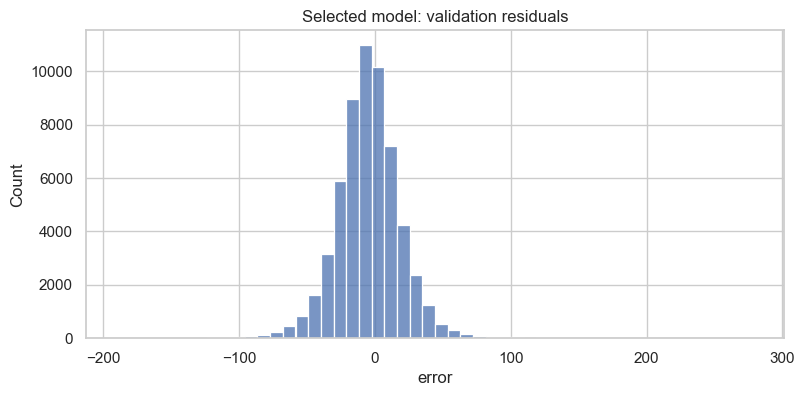

In [1322]:
# Inspect the validation error distribution.

plt.figure(figsize=(9, 4))
sns.histplot(residual_data['error'], bins=50)
plt.title('Selected model: validation residuals')
plt.show()

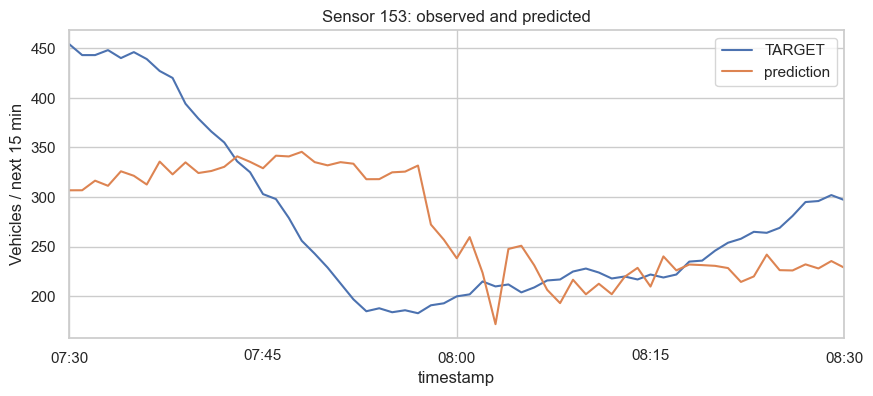

In [1323]:
# Plot actual and predicted flow for one sensor and date.

# Plot one sensor and date rather than connecting unrelated sensors.
example_sensor = sensor_ids[0]
example_date = residual_data['timestamp'].dt.normalize().min()
example = residual_data.loc[(residual_data['DP_ID'] == example_sensor) &
                            (residual_data['timestamp'].dt.normalize() == example_date)]
example.set_index('timestamp')[['TARGET', 'prediction']].plot(figsize=(10, 4))
plt.ylabel(TARGET_AXIS_LABEL)
plt.title(f'Sensor {example_sensor}: observed and predicted')
plt.show()

### 7.3 Sensor error

In [1324]:
# Identify sensors with larger prediction errors.

sensor_errors = residual_data.groupby('DP_ID')['absolute_error'].mean().sort_values(ascending=False)
display(sensor_errors.rename('MAE').to_frame())

,MAE
DP_ID,
536,29.093893
153,28.329602
534,27.345710
1443,26.738467
1254,26.703936
4472,23.498321
4429,23.057132
4427,22.581499
353,20.160820


### 7.4 Error by portal

In [1325]:
# Compare prediction errors across portal locations.

portal_errors = residual_data.groupby('PORTAL')['absolute_error'].mean().sort_values(ascending=False)
display(portal_errors.rename('MAE').to_frame())

,MAE
PORTAL,
"E4S 57,055",21.204147
"E4S 55,620",19.793795
"E4S 56,160",19.782215
"E4S 56,490",19.695747
"E4S 56,780",18.582635
"E4S 57,435",18.406370
"E4S 57,820",16.302147
"E4S 58,140",16.261997


### 7.5 Unusual traffic

Speed is used for diagnostics, while prediction inputs remain flow-only.

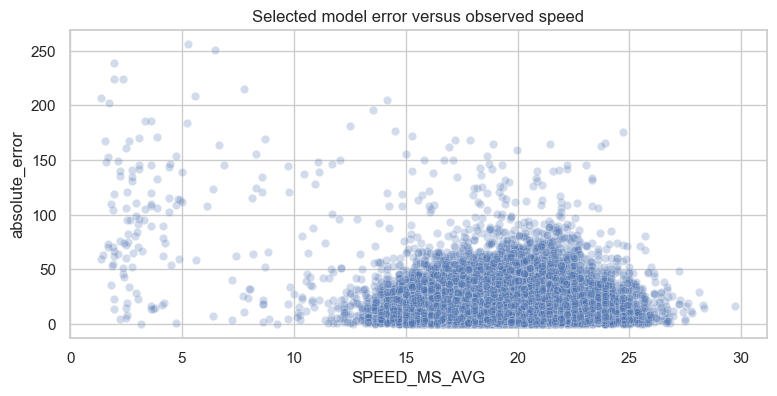

In [1326]:
# Inspect whether errors increase under different speed conditions.

diagnostic_sample = residual_data.sample(min(20000, len(residual_data)), random_state=RANDOM_STATE)
plt.figure(figsize=(9, 4))
sns.scatterplot(data=diagnostic_sample, x='SPEED_MS_AVG', y='absolute_error', alpha=.25)
plt.title('Selected model error versus observed speed')
plt.show()

### 7.6 Robustness to missing and noisy inputs

Change inputs only, keeping the observed targets fixed.

In [1327]:
# Prepare a common sample for the robustness scenarios.

robustness_data = bounded_sample(validation_data, MAX_TUNING_ROWS)
X_robust = configuration_inputs(robustness_data, best_configuration)
flow_columns = [name for name in X_robust if name.startswith('FLOW') and name != 'FLOW_was_missing']
robustness_results = []

In [1328]:
# Test missing flow inputs and flow noise.

for scenario in ['Original', '10% missing flow inputs', '10% flow noise']:
    rng = np.random.default_rng(RANDOM_STATE)
    inputs = X_robust.copy()
    values = inputs[flow_columns].to_numpy(copy=True)
    # Do not alter structural zeros that mark excluded spatial sensors.
    active = ~np.isnan(values) & (values != 0)
    if scenario == '10% missing flow inputs':
        values[(rng.random(values.shape) < .1) & active] = np.nan
    elif scenario == '10% flow noise':
        values[active] = np.maximum(0, values[active] * (1 + rng.normal(0, .1, values.shape)[active]))
    inputs[flow_columns] = values
    robustness_results.append({'Scenario': scenario,
                               **calculate_metrics(robustness_data['TARGET'],
                                                   predict_flow(best_validation_model, inputs))})

In [1329]:
# Compare robustness metrics.

robustness_results = pd.DataFrame(robustness_results)
display(robustness_results)
robustness_results.to_csv(OUTPUT_DIR / 'robustness_results.csv', index=False)

,Scenario,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,Original,18.555390,26.030646,11.202879,0,0.918178,6000
1,10% missing flow inputs,20.555297,28.361474,12.781675,0,0.902869,6000
2,10% flow noise,20.467274,28.152677,11.822113,0,0.904294,6000


## 8. Train the final model

Freeze the configuration, algorithm and parameters selected on 2021 data. Refit the selected pipeline on the eligible 2021 development data using the configured training-row limit. Only then load the final 2022 evaluation file.

In [1330]:
# Refit with the configured sample limit across all eligible 2021 data.

final_training_sample = bounded_sample(development_data, MAX_TRAIN_ROWS)
final_model = clone(selected_pipelines[best_algorithm])
final_model.fit(configuration_inputs(final_training_sample, best_configuration),
                final_training_sample['TARGET'])

TransformedTargetRegressor(regressor=Pipeline(steps=[('imputer',
                                                      SimpleImputer(add_indicator=True,
                                                                    keep_empty_features=True,
                                                                    strategy='median')),
                                                     ('scaler',
                                                      StandardScaler()),
                                                     ('model',
                                                      XGBRegressor(base_score=None,
                                                                   booster=None,
                                                                   callbacks=None,
                                                                   colsample_bylevel=None,
                                                                   colsample_bynode=None,
                                                                   colsample_bytree=1.0,
                                                                   device=None,
                                                                   early_stopping_rounds=None,
                                                                   enable_ca...
                                                                   importance_type=None,
                                                                   interaction_constraints=None,
                                                                   learning_rate=0.1,
                                                                   max_bin=None,
                                                                   max_cat_threshold=None,
                                                                   max_cat_to_onehot=None,
                                                                   max_delta_step=None,
                                                                   max_depth=6,
                                                                   max_leaves=None,
                                                                   min_child_weight=1,
                                                                   missing=nan,
                                                                   monotone_constraints=None,
                                                                   multi_strategy=None,
                                                                   n_estimators=100,
                                                                   n_jobs=2,
                                                                   num_parallel_tree=None,
                                                                   random_state=42, ...))]),
                           transformer=StandardScaler())

In [1331]:
# Load 2022 data only after model selection is complete.

evaluation_raw = pd.read_csv(FINAL_EVAL_PATH, sep=';')
assert pd.to_datetime(evaluation_raw['Date'].astype(str)).min() > development_data['timestamp'].max().normalize()

In [1332]:
# Preserve every prediction minute and report scorable coverage.

evaluation_all, evaluation_coverage = build_features(evaluation_raw)
display(evaluation_coverage)

,Expected_sensor_minutes,Scorable_targets,Unscorable_targets,Coverage_percent
0,160979,125470,35509,77.941843


### Final rolling evaluation

Use the identical minute-grid feature builder and frozen model for every prediction timestamp during the morning peak. Predict every sensor-minute, but score only targets satisfying the selected mode: complete observed windows or observed exact-horizon endpoints. Report the unscorable target count and coverage instead of fabricating ground truth.

In [1333]:
# Predict the selected window or exact-horizon FLOW target every morning-peak minute.

evaluation_all['prediction'] = predict_flow(final_model, configuration_inputs(evaluation_all, best_configuration))
evaluation_scored = evaluation_all.dropna(subset=['TARGET']).copy()

## 9. Final results

### 9.1 Overall final-evaluation metrics

In [1334]:
# Report independent 2022 performance.

final_results = pd.DataFrame([{'Algorithm': best_algorithm, 'Configuration': best_configuration,
                               **calculate_metrics(evaluation_scored['TARGET'], evaluation_scored['prediction'])}])
display(final_results)

,Algorithm,Configuration,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,XGBoost,D,17.871588,24.508157,9.819341,0,0.927763,125470


### 9.2 Performance by month, sensor and portal

In [1335]:
# Calculate comparable metrics for each subgroup.

def grouped_metrics(data, column):
    records = []
    for group, part in data.groupby(column):
        records.append({column: str(group), **calculate_metrics(part['TARGET'], part['prediction'])})
    return pd.DataFrame(records)

In [1336]:
# Check generalizability across months and locations.

evaluation_scored['month'] = evaluation_scored['timestamp'].dt.to_period('M').astype(str)
monthly_results = grouped_metrics(evaluation_scored, 'month')
final_sensor_results = grouped_metrics(evaluation_scored, 'DP_ID')
final_portal_results = grouped_metrics(evaluation_scored, 'PORTAL')
display(monthly_results)
display(final_sensor_results)
display(final_portal_results)

,month,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,2022-01,16.473281,22.002266,11.917533,0,0.928390,11066
1,2022-02,18.381649,25.238735,9.800293,0,0.921295,25635
2,2022-03,17.886236,24.077759,9.869498,0,0.932943,21399
3,2022-04,17.859343,25.170770,9.458821,0,0.923670,24198
4,2022-05,18.256659,25.173957,9.853574,0,0.918492,19367
5,2022-06,17.658332,23.960723,9.158022,0,0.925869,23805


,DP_ID,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,153,24.823748,33.129204,13.467787,0,0.733654,4725
1,351,16.749396,22.733611,8.809457,0,0.799481,5117
2,353,17.700049,22.899793,7.840717,0,0.892561,5184
3,534,24.634485,32.199523,15.423272,0,0.689201,4630
4,536,25.178384,33.083318,14.111620,0,0.733950,4633
5,539,14.676150,19.271951,7.370545,0,0.846812,4893
6,543,16.904354,22.789897,7.319708,0,0.895498,5205
7,740,16.251703,21.923560,5.637397,0,0.889369,5190
8,749,15.611911,21.234044,5.294899,0,0.901038,5215
9,751,15.753997,20.883539,5.863470,0,0.857383,5121


,PORTAL,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
0,"E4S 55,620",19.174700,26.035851,9.097346,0,0.860258,14793
1,"E4S 56,160",18.538203,25.250418,8.881578,0,0.895569,14716
2,"E4S 56,490",18.423738,25.103942,10.236443,0,0.898551,18865
3,"E4S 56,780",17.831123,24.597677,10.813477,0,0.930926,17954
4,"E4S 57,055",19.209370,26.007198,8.714549,0,0.897518,15258
5,"E4S 57,435",18.191100,25.001912,8.532701,0,0.930323,14015
6,"E4S 57,820",16.407180,22.884244,10.054738,0,0.952663,11604
7,"E4S 58,140",15.316237,20.985309,11.512246,0,0.956270,18265


### 9.3 Visualize the final best result

The figure combines all scored 2022 predictions, one representative sensor-day, the prediction-error distribution and monthly accuracy. Points closer to the diagonal and overlapping forecast/observed curves indicate better predictions. Residuals are predicted minus observed flow, so positive values indicate overprediction. All values use the selected future horizon and window/point target mode; plot labels and error units follow the Section 1 settings.

The example is selected by proximity to the median sensor-day MAE among days with at least 50 scorable minutes. The header reports the final model metrics, and the footer reports missing-target coverage.

In [1337]:
# Prepare the scored final-evaluation observations.

import matplotlib.dates as mdates

final_plot_data = evaluation_scored.copy()
final_plot_data['prediction_error'] = final_plot_data['prediction'] - final_plot_data['TARGET']
final_plot_data['absolute_error'] = final_plot_data['prediction_error'].abs()
final_plot_data['date'] = final_plot_data['timestamp'].dt.normalize()
final_metric = final_results.iloc[0]
final_coverage = evaluation_coverage.iloc[0]

In [1338]:
# Choose a representative sensor-day using its measured MAE.

sensor_day_errors = final_plot_data.groupby(['DP_ID', 'date']).agg(
    MAE=('absolute_error', 'mean'), N=('absolute_error', 'size'))
eligible_days = sensor_day_errors.loc[sensor_day_errors['N'] >= 50]
if eligible_days.empty:
    eligible_days = sensor_day_errors
example_sensor, example_date = (eligible_days['MAE'] - eligible_days['MAE'].median()).abs().idxmin()
final_example = final_plot_data.loc[
    (final_plot_data['DP_ID'] == example_sensor) & (final_plot_data['date'] == example_date)]
# Retain NaNs at unscorable timestamps to show breaks in the plotted lines.
example_index = pd.date_range(example_date + pd.Timedelta(hours=7, minutes=30),
                              example_date + pd.Timedelta(hours=8, minutes=30), freq='min')
final_example = final_example.set_index('timestamp').reindex(example_index)

In [1370]:
# Create a four-panel figure with the final model metrics.

sns.set_theme(style='whitegrid', context='notebook')
final_figure, final_axes = plt.subplots(2, 2, figsize=(16, 9))
# Prevent Jupyter from displaying and auto-closing an unfinished figure.
# The figure object remains usable by the following plotting cells.
plt.close(final_figure)
final_figure.subplots_adjust(top=.82, bottom=.13, hspace=.44, wspace=.30)
final_figure.text(.06, .965,
    f"Final forecast performance: {final_metric['Algorithm']} + configuration {final_metric['Configuration']}",
    fontsize=19, weight='bold', color='#18334a')
final_figure.text(.06, .929,
    f'2022 benchmark | Morning peak 07:30–08:30 | {TARGET_DESCRIPTION}',
    fontsize=11, color='#526777')
final_figure.text(.06, .87,
    f"MAE  {final_metric['MAE']:.2f} {TARGET_UNIT}     RMSE  {final_metric['RMSE']:.2f} {TARGET_UNIT}     "
    f"MAPE  {final_metric['MAPE_percent']:.2f}%     R²  {final_metric['R2']:.3f}",
    fontsize=13, color='#18334a',
    bbox=dict(boxstyle='round,pad=.7', facecolor='#edf4f8', edgecolor='none'))

Text(0.06, 0.87, 'MAE  17.87 vehicles     RMSE  24.51 vehicles     MAPE  9.82%     R²  0.928')

In [1371]:
# Show agreement across every scored prediction with a density plot.

ax = final_axes[0, 0]
density = ax.hexbin(final_plot_data['TARGET'], final_plot_data['prediction'],
                    gridsize=45, mincnt=1, bins='log', cmap='Blues', linewidths=0)
limit = max(final_plot_data['TARGET'].max(), final_plot_data['prediction'].max()) * 1.03
ax.plot([0, limit], [0, limit], '--', color='#d65f32', linewidth=1.5, label='Perfect prediction')
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel=f'Observed {TARGET_AXIS_LABEL}',
       ylabel=f'Predicted {TARGET_AXIS_LABEL}', title='All final predictions versus observations')
ax.legend(loc='upper left', fontsize=9)
final_figure.colorbar(density, ax=ax, pad=.02).set_label('Prediction count (log scale)', fontsize=9)

In [1372]:
# Plot the rolling forecast against observations for the selected example.

ax = final_axes[0, 1]
ax.plot(final_example.index, final_example['TARGET'], color='#2274a5', linewidth=2, label='Observed')
ax.plot(final_example.index, final_example['prediction'], color='#d65f32', linewidth=2, label='Predicted')
ax.set(title=f'Sensor {example_sensor} · {example_date:%Y-%m-%d}',
       xlabel='Prediction time', ylabel=TARGET_AXIS_LABEL)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
ax.set_xlim(example_index[0], example_index[-1])
ax.legend(loc='best', fontsize=9)

In [1373]:
# Inspect the spread of errors and overall prediction bias.

ax = final_axes[1, 0]
ax.hist(final_plot_data['prediction_error'], bins=70, color='#2274a5', alpha=.85)
ax.axvline(0, color='#d65f32', linestyle='--', linewidth=1.5)
ax.set(title='Prediction-error distribution', xlabel=f'Predicted − observed ({TARGET_UNIT})',
       ylabel='Number of predictions')
mean_error = final_plot_data['prediction_error'].mean()
ax.text(.97, .93, f'Mean error: {mean_error:+.2f} {TARGET_UNIT}',
        transform=ax.transAxes, ha='right', va='top', fontsize=10,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.85))

Text(0.97, 0.93, 'Mean error: +1.96 vehicles')

In [1374]:
# Compare monthly errors and report evaluation coverage.

ax = final_axes[1, 1]
month_labels = pd.to_datetime(monthly_results['month']).dt.strftime('%b')
ax.plot(month_labels, monthly_results['MAE'], 'o-', color='#2274a5', linewidth=2, label='MAE')
ax.plot(month_labels, monthly_results['RMSE'], 'o-', color='#d65f32', linewidth=2, label='RMSE')
ax.set(title='Accuracy across evaluation months', xlabel='2022 month', ylabel=f'Error ({TARGET_UNIT})', ylim=(0, None))
ax.legend(loc='best', fontsize=9)
final_figure.text(.06, .062,
    f"Scored {int(final_metric['N']):,} of {int(final_coverage['Expected_sensor_minutes']):,} sensor-minutes "
    f"({final_coverage['Coverage_percent']:.1f}% target coverage). Missing future targets are excluded from metrics.",
    fontsize=10, color='#526777')
final_figure.text(.06, .038,
    'Example selected near median sensor-day MAE; forecast windows overlap. The 2022 benchmark has been reused.',
    fontsize=9, color='#526777')

Text(0.06, 0.038, 'Example selected near median sensor-day MAE; forecast windows overlap. The 2022 benchmark has been reused.')

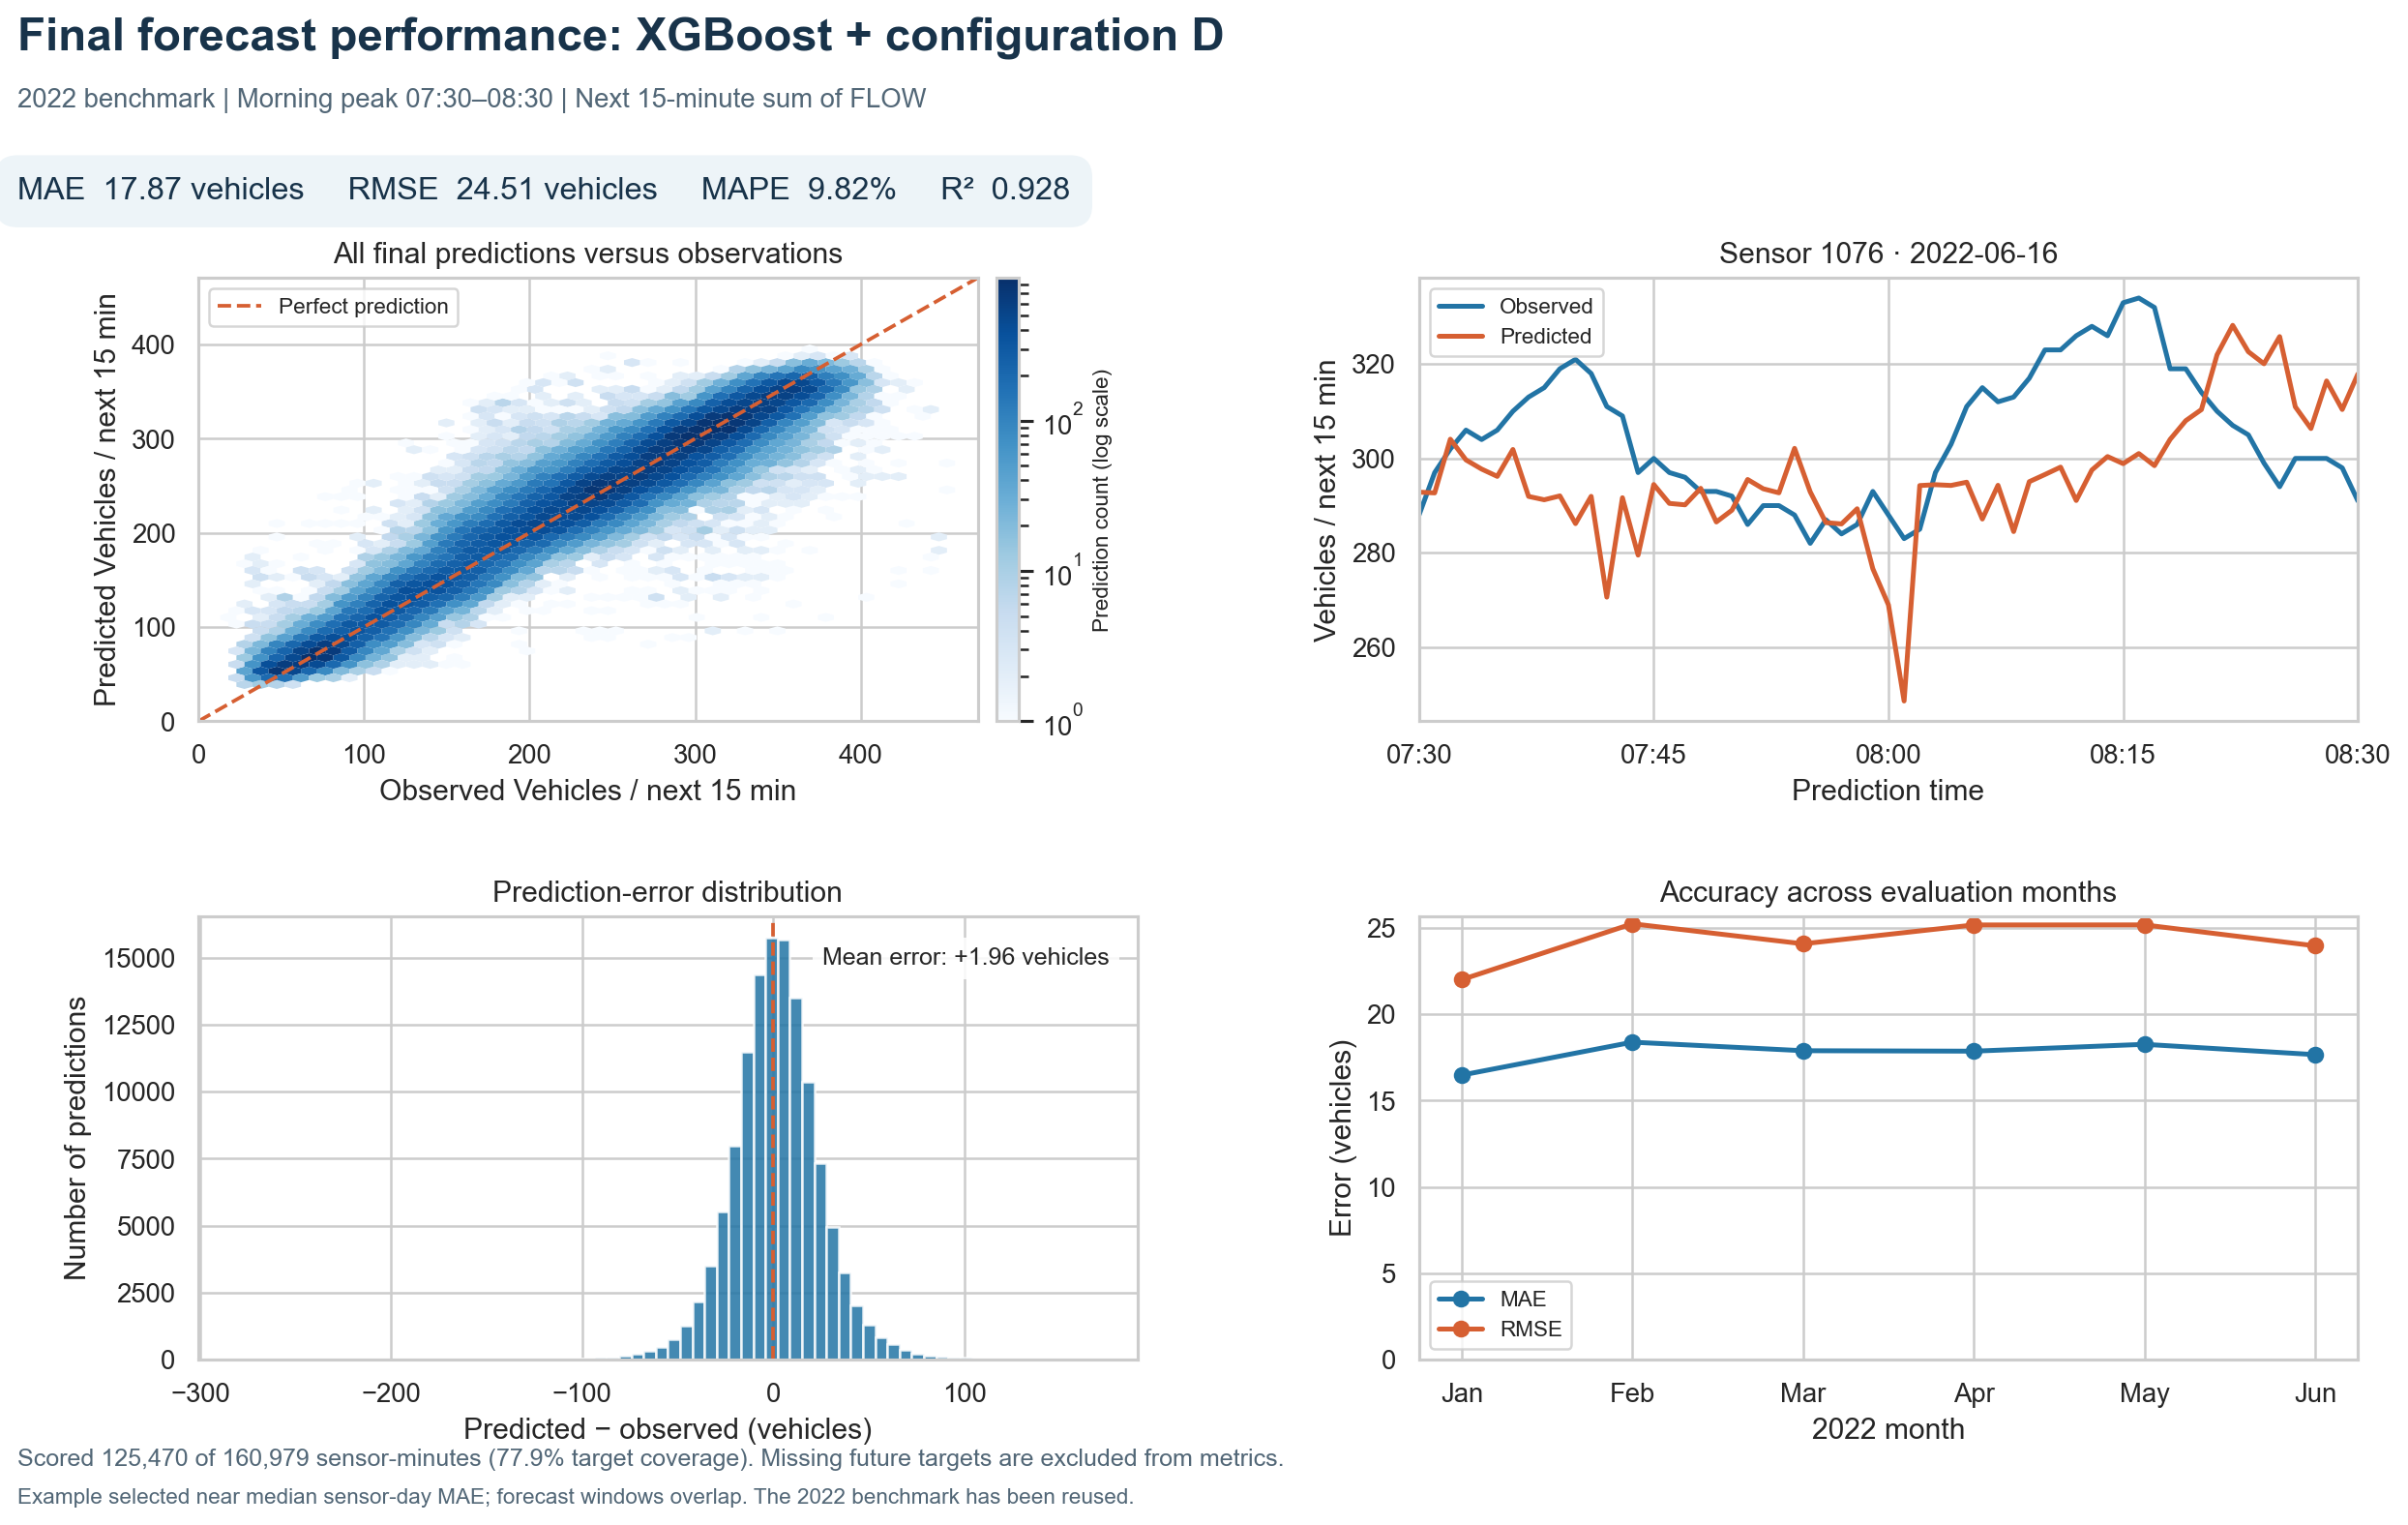

Saved final-performance graph: /Users/samuel/Library/CloudStorage/OneDrive-Personal/KTH/26fall_P1/AH2179/AH2179_Project/model_results/15min_sum/final_best_model_performance.png


In [1375]:
# Save and explicitly display the completed four-panel figure.

from IPython.display import Image, display

final_graph_path = OUTPUT_DIR / 'final_best_model_performance.png'
final_figure.savefig(final_graph_path, dpi=180, bbox_inches='tight', facecolor='white')
# Display the saved image even when the inline backend has closed pyplot figures.
display(Image(filename=str(final_graph_path), width=1100))
plt.close(final_figure)
print('Saved final-performance graph:', final_graph_path)

### 9.4 Prediction versus observed: both evaluation datasets

Apply the frozen final model to `evaluation_dataset.csv` as an additional benchmark. Compare its predictions with the existing `final_evaluation_dataset.csv` predictions. Both plots use exactly the same preprocessing, morning-peak window, target definition and selected model; no fitting or parameter selection takes place here.

In [1345]:
# Predict the additional evaluation file using the frozen best model.

evaluation_dataset_raw = pd.read_csv(EVAL_PATH, sep=';')
evaluation_dataset_all, evaluation_dataset_coverage = build_features(evaluation_dataset_raw)
evaluation_dataset_all['prediction'] = predict_flow(
    final_model, configuration_inputs(evaluation_dataset_all, best_configuration))
evaluation_dataset_scored = evaluation_dataset_all.dropna(subset=['TARGET']).copy()
if evaluation_dataset_scored.empty:
    raise ValueError(f'No observed targets for {TARGET_DESCRIPTION} in evaluation_dataset.csv.')

In [1346]:
# Report both datasets without changing the selected model.

comparison_datasets = {
    'Final evaluation dataset': evaluation_scored.copy(),
    'Evaluation dataset': evaluation_dataset_scored.copy()
}
comparison_coverages = {
    'Final evaluation dataset': evaluation_coverage.iloc[0],
    'Evaluation dataset': evaluation_dataset_coverage.iloc[0]
}
comparison_records = []
for label, data in comparison_datasets.items():
    data['date'] = data['timestamp'].dt.normalize()
    data['absolute_error'] = (data['prediction'] - data['TARGET']).abs()
    comparison_records.append({'Dataset': label,
                               **calculate_metrics(data['TARGET'], data['prediction']),
                               'Coverage_percent': comparison_coverages[label]['Coverage_percent']})
comparison_metrics = pd.DataFrame(comparison_records)
display(comparison_metrics)
comparison_metrics.to_csv(OUTPUT_DIR / 'both_evaluation_dataset_metrics.csv', index=False)

,Dataset,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N,Coverage_percent
0,Final evaluation dataset,17.871588,24.508157,9.819341,0,0.927763,125470,77.941843
1,Evaluation dataset,19.488803,27.090157,11.005475,0,0.915020,125696,78.949815


In [1347]:
# Plot the same prediction-agreement diagnostic for each dataset.

def plot_prediction_agreement(ax, data, title, limit):
    density = ax.hexbin(data['TARGET'], data['prediction'], gridsize=45,
                        bins='log', mincnt=1, cmap='Blues', linewidths=0)
    ax.plot([0, limit], [0, limit], '--', color='#d65f32', label='Perfect prediction')
    ax.set(xlim=(0, limit), ylim=(0, limit), title=title,
           xlabel=f'Observed {TARGET_AXIS_LABEL}', ylabel=f'Predicted {TARGET_AXIS_LABEL}')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(loc='upper left', fontsize=9)
    metrics = calculate_metrics(data['TARGET'], data['prediction'])
    ax.text(.97, .04, f"RMSE {metrics['RMSE']:.2f} | MAE {metrics['MAE']:.2f} | R² {metrics['R2']:.3f}",
            transform=ax.transAxes, ha='right', fontsize=9,
            bbox=dict(facecolor='white', edgecolor='none', alpha=.85))
    return density

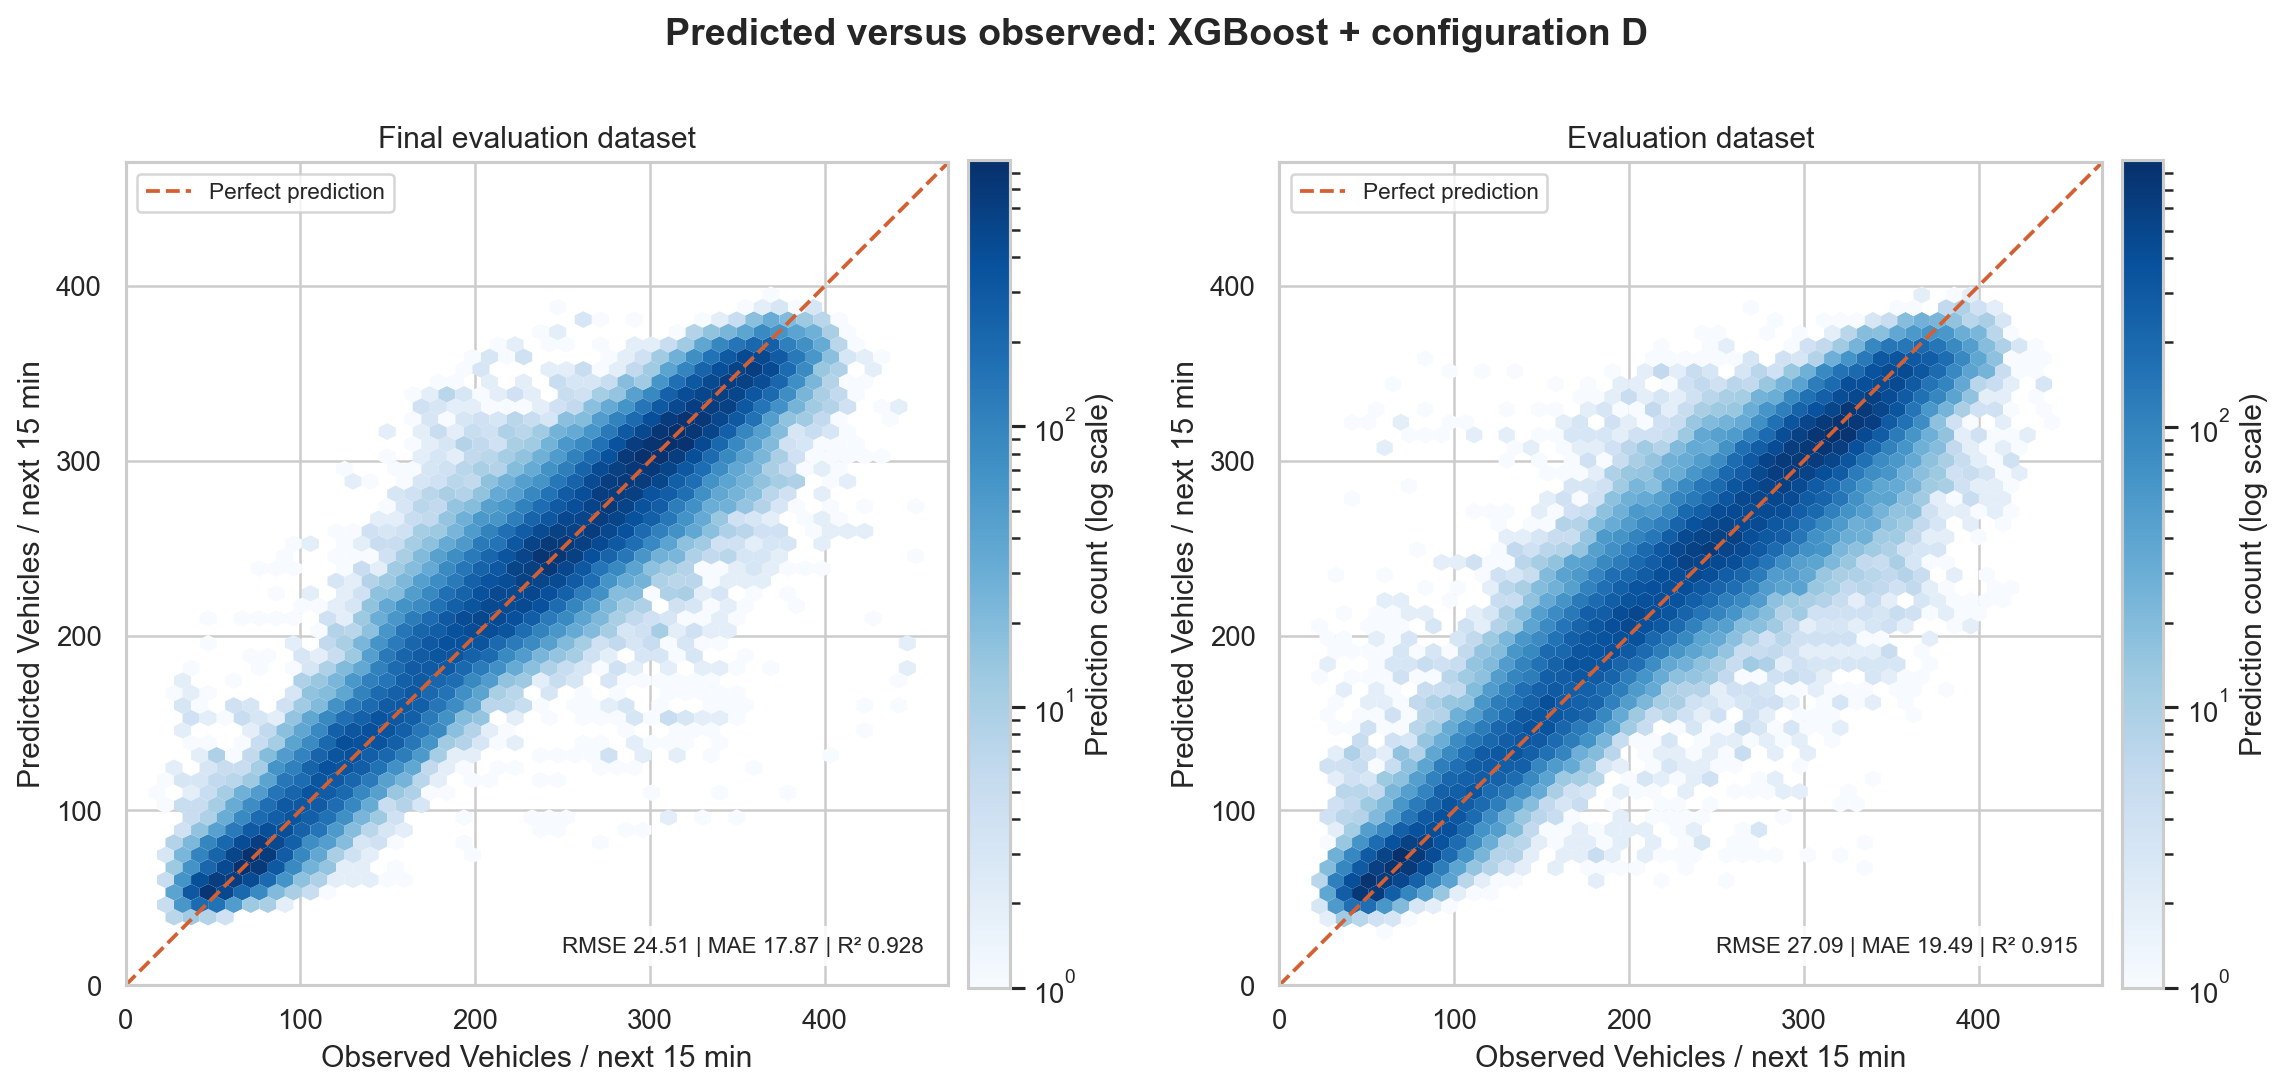

Saved: /Users/samuel/Library/CloudStorage/OneDrive-Personal/KTH/26fall_P1/AH2179/AH2179_Project/model_results/15min_sum/predicted_vs_observed_both_datasets.png


In [1348]:
# Display both agreement plots with identical axes and the current model title.

from IPython.display import Image, display

agreement_limit = max(max(data['TARGET'].max(), data['prediction'].max())
                      for data in comparison_datasets.values()) * 1.03
agreement_figure, agreement_axes = plt.subplots(1, 2, figsize=(13, 6))
plt.close(agreement_figure)
for ax, (label, data) in zip(agreement_axes, comparison_datasets.items()):
    density = plot_prediction_agreement(ax, data, label, agreement_limit)
    agreement_figure.colorbar(density, ax=ax, pad=.02).set_label('Prediction count (log scale)')
agreement_figure.suptitle(f'Predicted versus observed: {best_algorithm} + configuration {best_configuration}',
                         fontsize=15, weight='bold')
agreement_figure.tight_layout(rect=(0, .03, 1, .94))
agreement_graph_path = OUTPUT_DIR / 'predicted_vs_observed_both_datasets.png'
agreement_figure.savefig(agreement_graph_path, dpi=180, bbox_inches='tight', facecolor='white')
display(Image(filename=str(agreement_graph_path), width=1100))
print('Saved:', agreement_graph_path)

In [1349]:
# Choose a matched representative example rather than the best-fitting day.

comparison_day_summaries = {
    label: data.groupby(['DP_ID', 'date']).agg(MAE=('absolute_error', 'mean'), N=('TARGET', 'size'))
    for label, data in comparison_datasets.items()
}
summary_final, summary_evaluation = comparison_day_summaries.values()
common_days = summary_final.join(summary_evaluation, how='inner', lsuffix='_final', rsuffix='_evaluation')
eligible_common = common_days.loc[(common_days['N_final'] >= 50) & (common_days['N_evaluation'] >= 50)]
if eligible_common.empty:
    eligible_common = common_days
common_example = None
if not eligible_common.empty:
    mean_day_mae = eligible_common[['MAE_final', 'MAE_evaluation']].mean(axis=1)
    common_example = (mean_day_mae - mean_day_mae.median()).abs().idxmin()
print('Common sensor-day example:', common_example)

Common sensor-day example: None


In [1350]:
# Preserve line breaks where a future target cannot be observed.

def select_comparison_example(data, summary, common_key):
    if common_key is None:
        eligible = summary.loc[summary['N'] >= 50]
        if eligible.empty:
            eligible = summary
        key = (eligible['MAE'] - eligible['MAE'].median()).abs().idxmin()
    else:
        key = common_key
    sensor, date = key
    part = data.loc[(data['DP_ID'] == sensor) & (data['date'] == date)].set_index('timestamp')
    minute_index = pd.date_range(date + pd.Timedelta(hours=7, minutes=30),
                                date + pd.Timedelta(hours=8, minutes=30), freq='min')
    return part.reindex(minute_index), sensor, date

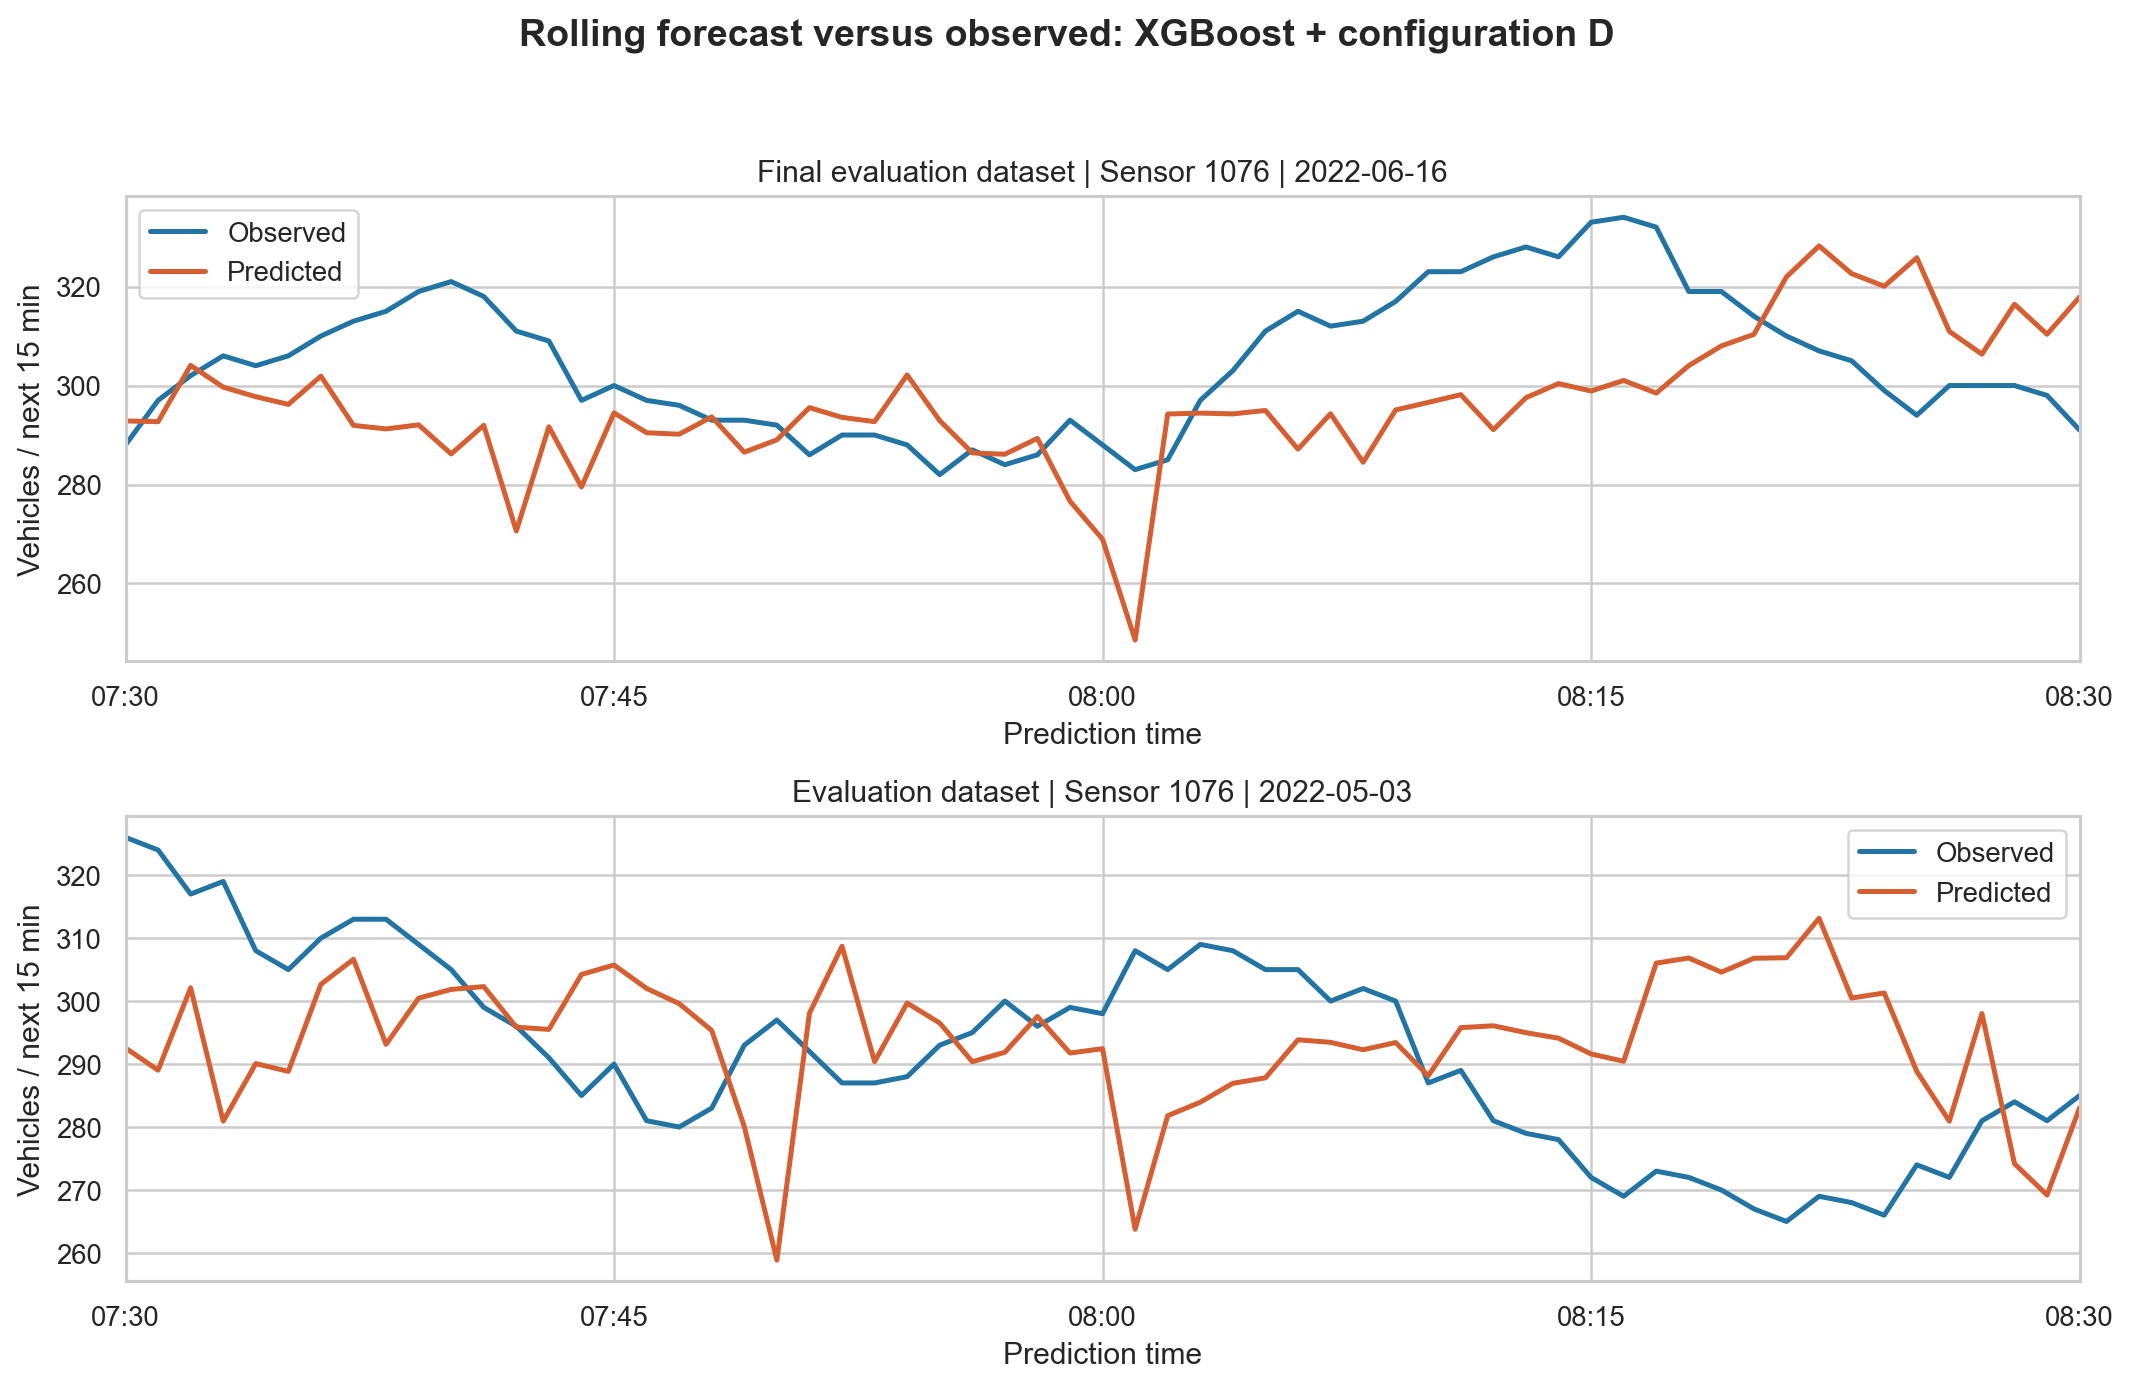

Saved: /Users/samuel/Library/CloudStorage/OneDrive-Personal/KTH/26fall_P1/AH2179/AH2179_Project/model_results/15min_sum/rolling_prediction_vs_observed_both_datasets.png


In [1351]:
# Display rolling predicted-versus-observed curves for both files.

import matplotlib.dates as mdates

rolling_figure, rolling_axes = plt.subplots(2, 1, figsize=(12, 8))
plt.close(rolling_figure)
for ax, (label, data) in zip(rolling_axes, comparison_datasets.items()):
    example, sensor, date = select_comparison_example(data, comparison_day_summaries[label], common_example)
    ax.plot(example.index, example['TARGET'], color='#2274a5', linewidth=2, label='Observed')
    ax.plot(example.index, example['prediction'], color='#d65f32', linewidth=2, label='Predicted')
    ax.set(title=f'{label} | Sensor {sensor} | {date:%Y-%m-%d}',
           xlabel='Prediction time', ylabel=TARGET_AXIS_LABEL)
    ax.set_xlim(example.index[0], example.index[-1])
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.legend(loc='best')
rolling_figure.suptitle(f'Rolling forecast versus observed: {best_algorithm} + configuration {best_configuration}',
                       fontsize=15, weight='bold')
rolling_figure.tight_layout(rect=(0, .02, 1, .95))
rolling_graph_path = OUTPUT_DIR / 'rolling_prediction_vs_observed_both_datasets.png'
rolling_figure.savefig(rolling_graph_path, dpi=180, bbox_inches='tight', facecolor='white')
display(Image(filename=str(rolling_graph_path), width=1100))
print('Saved:', rolling_graph_path)

### 9.5 Model fit within versus outside the morning rush-hour window


In [1352]:
# Define the diagnostic window without changing the training window.

RUSH_START_MINUTE = 7 * 60 + 30
RUSH_END_MINUTE = 8 * 60 + 30
DIAGNOSTIC_START_MINUTE = 5 * 60
DIAGNOSTIC_END_MINUTE = 10 * 60 - HORIZON
rush_diagnostic_datasets = {}
print(f'Diagnostic start times: 05:00–{DIAGNOSTIC_END_MINUTE // 60:02d}:'
      f'{DIAGNOSTIC_END_MINUTE % 60:02d}; target: {TARGET_DESCRIPTION}')


Diagnostic start times: 05:00–09:45; target: Next 15-minute sum of FLOW


In [1353]:
# Predict both morning-wide datasets with the same frozen final model.

history_columns = [name for name in baseline_features
                   if name.startswith('FLOW_lag_') or name.startswith('FLOW_previous_')]
for label, source_path in [('Final evaluation dataset', FINAL_EVAL_PATH),
                           ('Evaluation dataset', EVAL_PATH)]:
    raw = pd.read_csv(source_path, sep=';')
    rows, _ = build_features(raw, prediction_window=(DIAGNOSTIC_START_MINUTE,
                                                    DIAGNOSTIC_END_MINUTE))
    rows['prediction'] = predict_flow(final_model, configuration_inputs(rows, best_configuration))
    rows['full_own_history'] = rows[['FLOW'] + history_columns].notna().all(axis=1)
    minutes = rows['timestamp'].dt.hour * 60 + rows['timestamp'].dt.minute
    rows['rush_period'] = np.where(minutes.between(RUSH_START_MINUTE, RUSH_END_MINUTE),
                                   'Within rush window', 'Outside rush window')
    factor = TARGET_PERSISTENCE_FACTOR
    rows['persistence'] = rows['FLOW'] * factor
    columns = ['timestamp', 'DP_ID', 'PORTAL', 'TARGET', 'prediction', 'rush_period',
               'FLOW_was_missing', 'full_own_history', 'persistence']
    rush_diagnostic_datasets[label] = rows[columns].copy()
    del raw, rows


#### Within/outside metrics and coverage

MAE, RMSE and bias use the selected target units. `MAE_over_mean_percent` normalizes absolute error by mean observed flow; it is not MAPE. `Persistence_N` records the common subset used by both model and persistence for `RMSE_skill_percent`. Full-history errors are descriptive subset checks, not a replacement for coverage reporting.


In [1354]:
# Calculate each group's errors and its matched persistence comparison.

def rush_group_metrics(part):
    scored = part.dropna(subset=['TARGET', 'prediction'])
    record = {'Expected_sensor_minutes': len(part), 'Scorable_targets': len(scored),
              'Coverage_percent': 100 * len(scored) / len(part),
              'Current_FLOW_missing_percent': 100 * part['FLOW_was_missing'].mean(),
              'Full_own_history_percent': 100 * part['full_own_history'].mean()}
    if scored.empty:
        return record
    record.update(calculate_metrics(scored['TARGET'], scored['prediction']))
    mean_target = scored['TARGET'].mean()
    record.update({'Mean_target': mean_target,
                   'MAE_over_mean_percent': 100 * record['MAE'] / mean_target if mean_target else np.nan,
                   'Bias': (scored['prediction'] - scored['TARGET']).mean()})
    full = scored.loc[scored['full_own_history']]
    record['Full_history_N'] = len(full)
    record['Full_history_RMSE'] = (np.sqrt(np.mean((full['prediction'] - full['TARGET']) ** 2))
                                   if len(full) else np.nan)
    paired = scored.dropna(subset=['persistence'])
    record['Persistence_N'] = len(paired)
    if len(paired):
        model_rmse = np.sqrt(np.mean((paired['prediction'] - paired['TARGET']) ** 2))
        baseline_rmse = np.sqrt(np.mean((paired['persistence'] - paired['TARGET']) ** 2))
        record.update({'Matched_model_RMSE': model_rmse, 'Persistence_RMSE': baseline_rmse,
                       'RMSE_skill_percent': 100 * (1 - model_rmse / baseline_rmse)
                                             if baseline_rmse else np.nan})
    return record


In [1355]:
# Summarize period and hour; no row-level private predictions are exported.

rush_records, rush_hour_records = [], []
for label, data in rush_diagnostic_datasets.items():
    for period, part in data.groupby('rush_period', sort=False):
        rush_records.append({'Dataset': label, 'Period': period, **rush_group_metrics(part)})
    for hour, part in data.groupby(data['timestamp'].dt.hour):
        rush_hour_records.append({'Dataset': label, 'Hour': hour, **rush_group_metrics(part)})
rush_comparison = pd.DataFrame(rush_records)
rush_hourly_comparison = pd.DataFrame(rush_hour_records)
primary_columns = ['Dataset', 'Period', 'N', 'MAE', 'RMSE', 'MAPE_percent', 'R2', 'Coverage_percent']
display(rush_comparison[primary_columns].round(3))
diagnostic_columns = ['Dataset', 'Period', 'Mean_target', 'MAE_over_mean_percent',
                      'Bias', 'Full_history_RMSE', 'Current_FLOW_missing_percent',
                      'Matched_model_RMSE', 'Persistence_RMSE', 'RMSE_skill_percent']
display(rush_comparison[diagnostic_columns].round(3))
hourly_columns = ['Dataset', 'Hour', 'N', 'RMSE', 'R2', 'Coverage_percent']
display(rush_hourly_comparison[hourly_columns].round(3))
rush_comparison.to_csv(OUTPUT_DIR / 'rush_vs_outside_metrics.csv', index=False)
rush_hourly_comparison.to_csv(OUTPUT_DIR / 'rush_vs_outside_hourly_metrics.csv', index=False)


,Dataset,Period,N,MAE,RMSE,MAPE_percent,R2,Coverage_percent
0,Final evaluation dataset,Outside rush window,433314,21.592,29.708,12.148,0.900,72.976
1,Final evaluation dataset,Within rush window,125470,17.872,24.508,9.819,0.928,77.942
2,Evaluation dataset,Outside rush window,425927,21.655,29.362,12.563,0.904,72.529
3,Evaluation dataset,Within rush window,125696,19.489,27.090,11.005,0.915,78.950


,Dataset,Period,Mean_target,MAE_over_mean_percent,Bias,Full_history_RMSE,Current_FLOW_missing_percent,Matched_model_RMSE,Persistence_RMSE,RMSE_skill_percent
0,Final evaluation dataset,Outside rush window,222.958,9.684,-4.022,28.547,13.173,29.485,59.741,50.644
1,Final evaluation dataset,Within rush window,228.115,7.834,1.957,24.252,10.363,24.370,58.982,58.682
2,Evaluation dataset,Outside rush window,218.058,9.931,-4.021,28.523,12.190,29.115,59.285,50.890
3,Evaluation dataset,Within rush window,223.182,8.732,2.406,26.657,8.703,26.936,59.823,54.973


,Dataset,Hour,N,RMSE,R2,Coverage_percent
0,Final evaluation dataset,5,95389,33.720,0.883,60.243
1,Final evaluation dataset,6,112382,31.863,0.884,70.975
2,Final evaluation dataset,7,120947,26.005,0.925,76.384
3,Final evaluation dataset,8,126278,26.032,0.915,79.751
4,Final evaluation dataset,9,103788,25.573,0.917,85.497
5,Evaluation dataset,5,94109,34.125,0.878,60.095
6,Evaluation dataset,6,110432,30.817,0.895,70.519
7,Evaluation dataset,7,120106,27.464,0.918,76.696
8,Evaluation dataset,8,126433,25.989,0.920,80.736
9,Evaluation dataset,9,100543,26.195,0.915,83.744


In [1356]:
# Show the direction and size of the descriptive outside-minus-within difference.

rush_differences = []
for label, summary in rush_comparison.groupby('Dataset', sort=False):
    values = summary.set_index('Period')
    if not {'Within rush window', 'Outside rush window'}.issubset(values.index):
        continue
    inside, outside = values.loc['Within rush window'], values.loc['Outside rush window']
    difference = {'Dataset': label}
    for metric in ['MAE', 'RMSE', 'MAPE_percent', 'R2', 'MAE_over_mean_percent',
                   'Coverage_percent', 'Full_history_RMSE', 'RMSE_skill_percent']:
        difference[f'{metric}_outside_minus_within'] = outside.get(metric, np.nan) - inside.get(metric, np.nan)
    rush_differences.append(difference)
rush_performance_difference = pd.DataFrame(rush_differences)
display(rush_performance_difference.round(3))
rush_performance_difference.to_csv(OUTPUT_DIR / 'rush_vs_outside_differences.csv', index=False)


,Dataset,MAE_outside_minus_within,RMSE_outside_minus_within,MAPE_percent_outside_minus_within,R2_outside_minus_within,MAE_over_mean_percent_outside_minus_within,Coverage_percent_outside_minus_within,Full_history_RMSE_outside_minus_within,RMSE_skill_percent_outside_minus_within
0,Final evaluation dataset,3.720,5.200,2.329,-0.028,1.850,-4.966,4.296,-8.037
1,Evaluation dataset,2.166,2.272,1.558,-0.011,1.198,-6.421,1.865,-4.083


#### Prediction agreement and hourly fit

Each evaluation file gets a four-panel figure: observed versus predicted within/outside the window (shared axes), hourly RMSE with a persistence reference, and normalized MAE by period. These are predictive-fit diagnostics on evaluation observations, not training-fit plots. Hourly intervals include only the diagnostic prediction timestamps; the last hour may be partial.


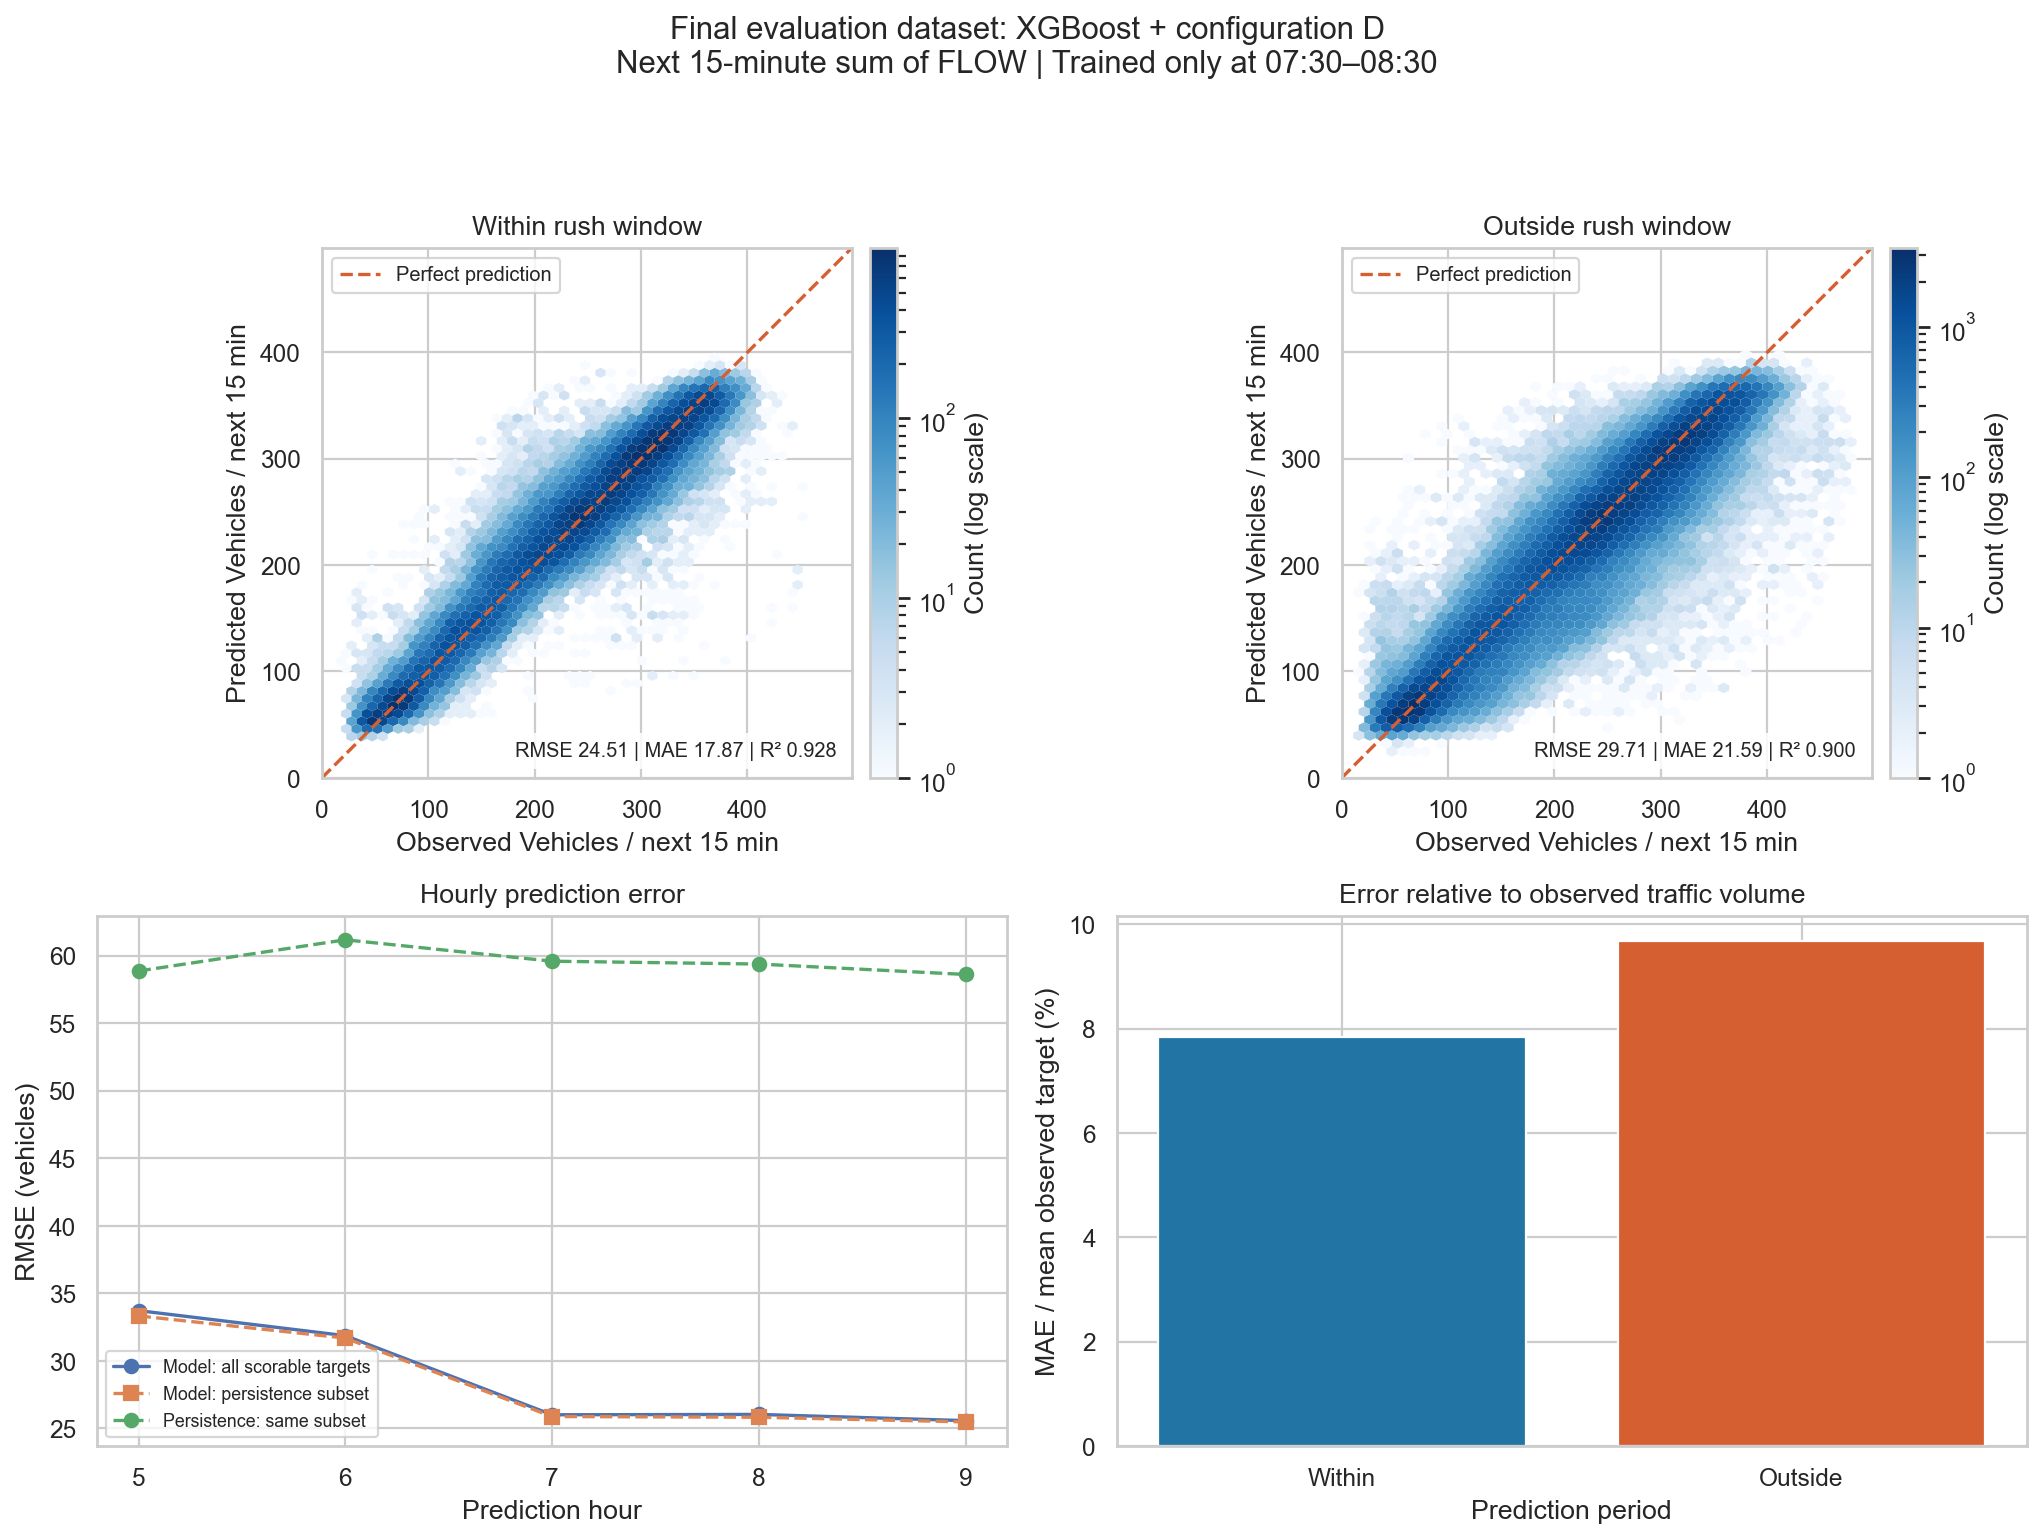

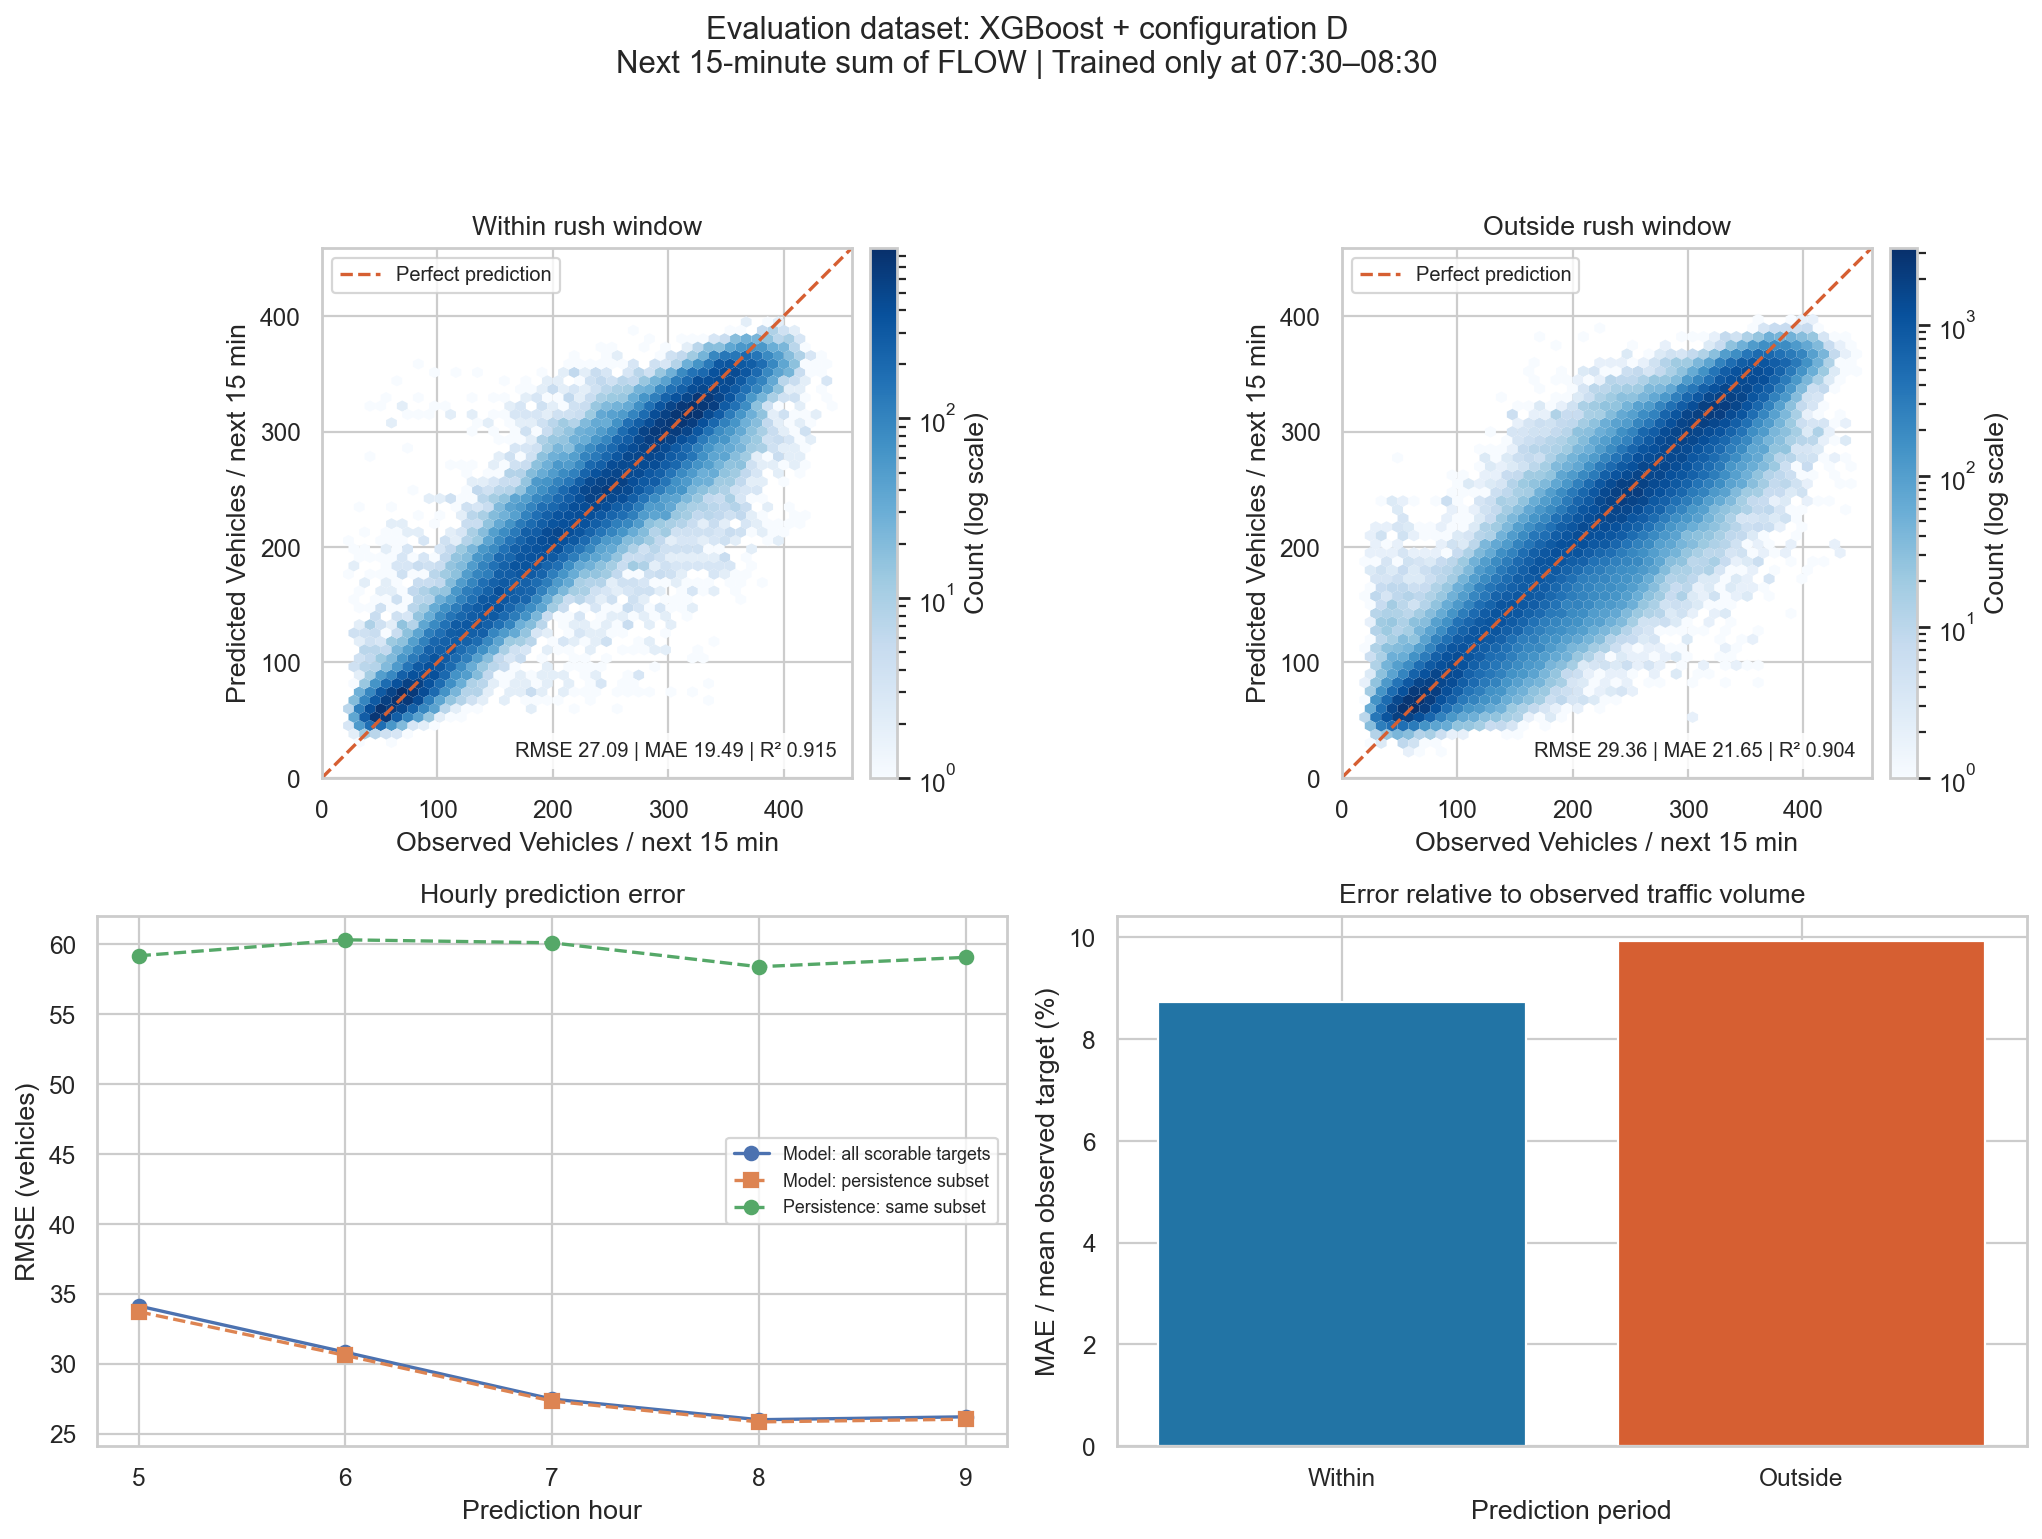

In [1357]:
# Draw all scored points and compare model/persistence errors by time of day.

from IPython.display import Image, display

rush_graph_paths = []
for label, data in rush_diagnostic_datasets.items():
    scored = data.dropna(subset=['TARGET', 'prediction'])
    figure, axes = plt.subplots(2, 2, figsize=(13, 10))
    plt.close(figure)
    limit = max(scored['TARGET'].max(), scored['prediction'].max()) * 1.03
    for ax, period in zip(axes[0], ['Within rush window', 'Outside rush window']):
        part = scored.loc[scored['rush_period'] == period]
        if part.empty:
            ax.text(.5, .5, 'No scorable targets', transform=ax.transAxes, ha='center')
            continue
        density = plot_prediction_agreement(ax, part, period, limit)
        figure.colorbar(density, ax=ax, pad=.02).set_label('Count (log scale)')
    hourly = rush_hourly_comparison.loc[rush_hourly_comparison['Dataset'] == label]
    ax = axes[1, 0]
    ax.plot(hourly['Hour'], hourly['RMSE'], 'o-', label='Model: all scorable targets')
    ax.plot(hourly['Hour'], hourly['Matched_model_RMSE'], 's--', label='Model: persistence subset')
    ax.plot(hourly['Hour'], hourly['Persistence_RMSE'], 'o--', label='Persistence: same subset')
    ax.set(title='Hourly prediction error', xlabel='Prediction hour', ylabel=f'RMSE ({TARGET_UNIT})')
    ax.set_xticks(hourly['Hour'])
    ax.legend(fontsize=8)
    summary = rush_comparison.loc[rush_comparison['Dataset'] == label].set_index('Period')
    summary = summary.reindex(['Within rush window', 'Outside rush window'])
    axes[1, 1].bar(['Within', 'Outside'], summary['MAE_over_mean_percent'], color=['#2274a5', '#d65f32'])
    axes[1, 1].set(title='Error relative to observed traffic volume',
                    ylabel='MAE / mean observed target (%)', xlabel='Prediction period')
    figure.suptitle(f'{label}: {best_algorithm} + configuration {best_configuration}\n'
                   f'{TARGET_DESCRIPTION} | Trained only at 07:30–08:30', fontsize=14)
    figure.tight_layout(rect=(0, .02, 1, .93))
    name = 'final_evaluation' if label == 'Final evaluation dataset' else 'evaluation'
    graph_path = OUTPUT_DIR / f'rush_vs_outside_{name}.png'
    figure.savefig(graph_path, dpi=160, bbox_inches='tight', facecolor='white')
    display(Image(filename=str(graph_path), width=1100))
    rush_graph_paths.append(graph_path)


Saved: /Users/samuel/Library/CloudStorage/OneDrive-Personal/KTH/26fall_P1/AH2179/AH2179_Project/model_results/15min_sum/forecast_vs_observed_within_outside_rush.png


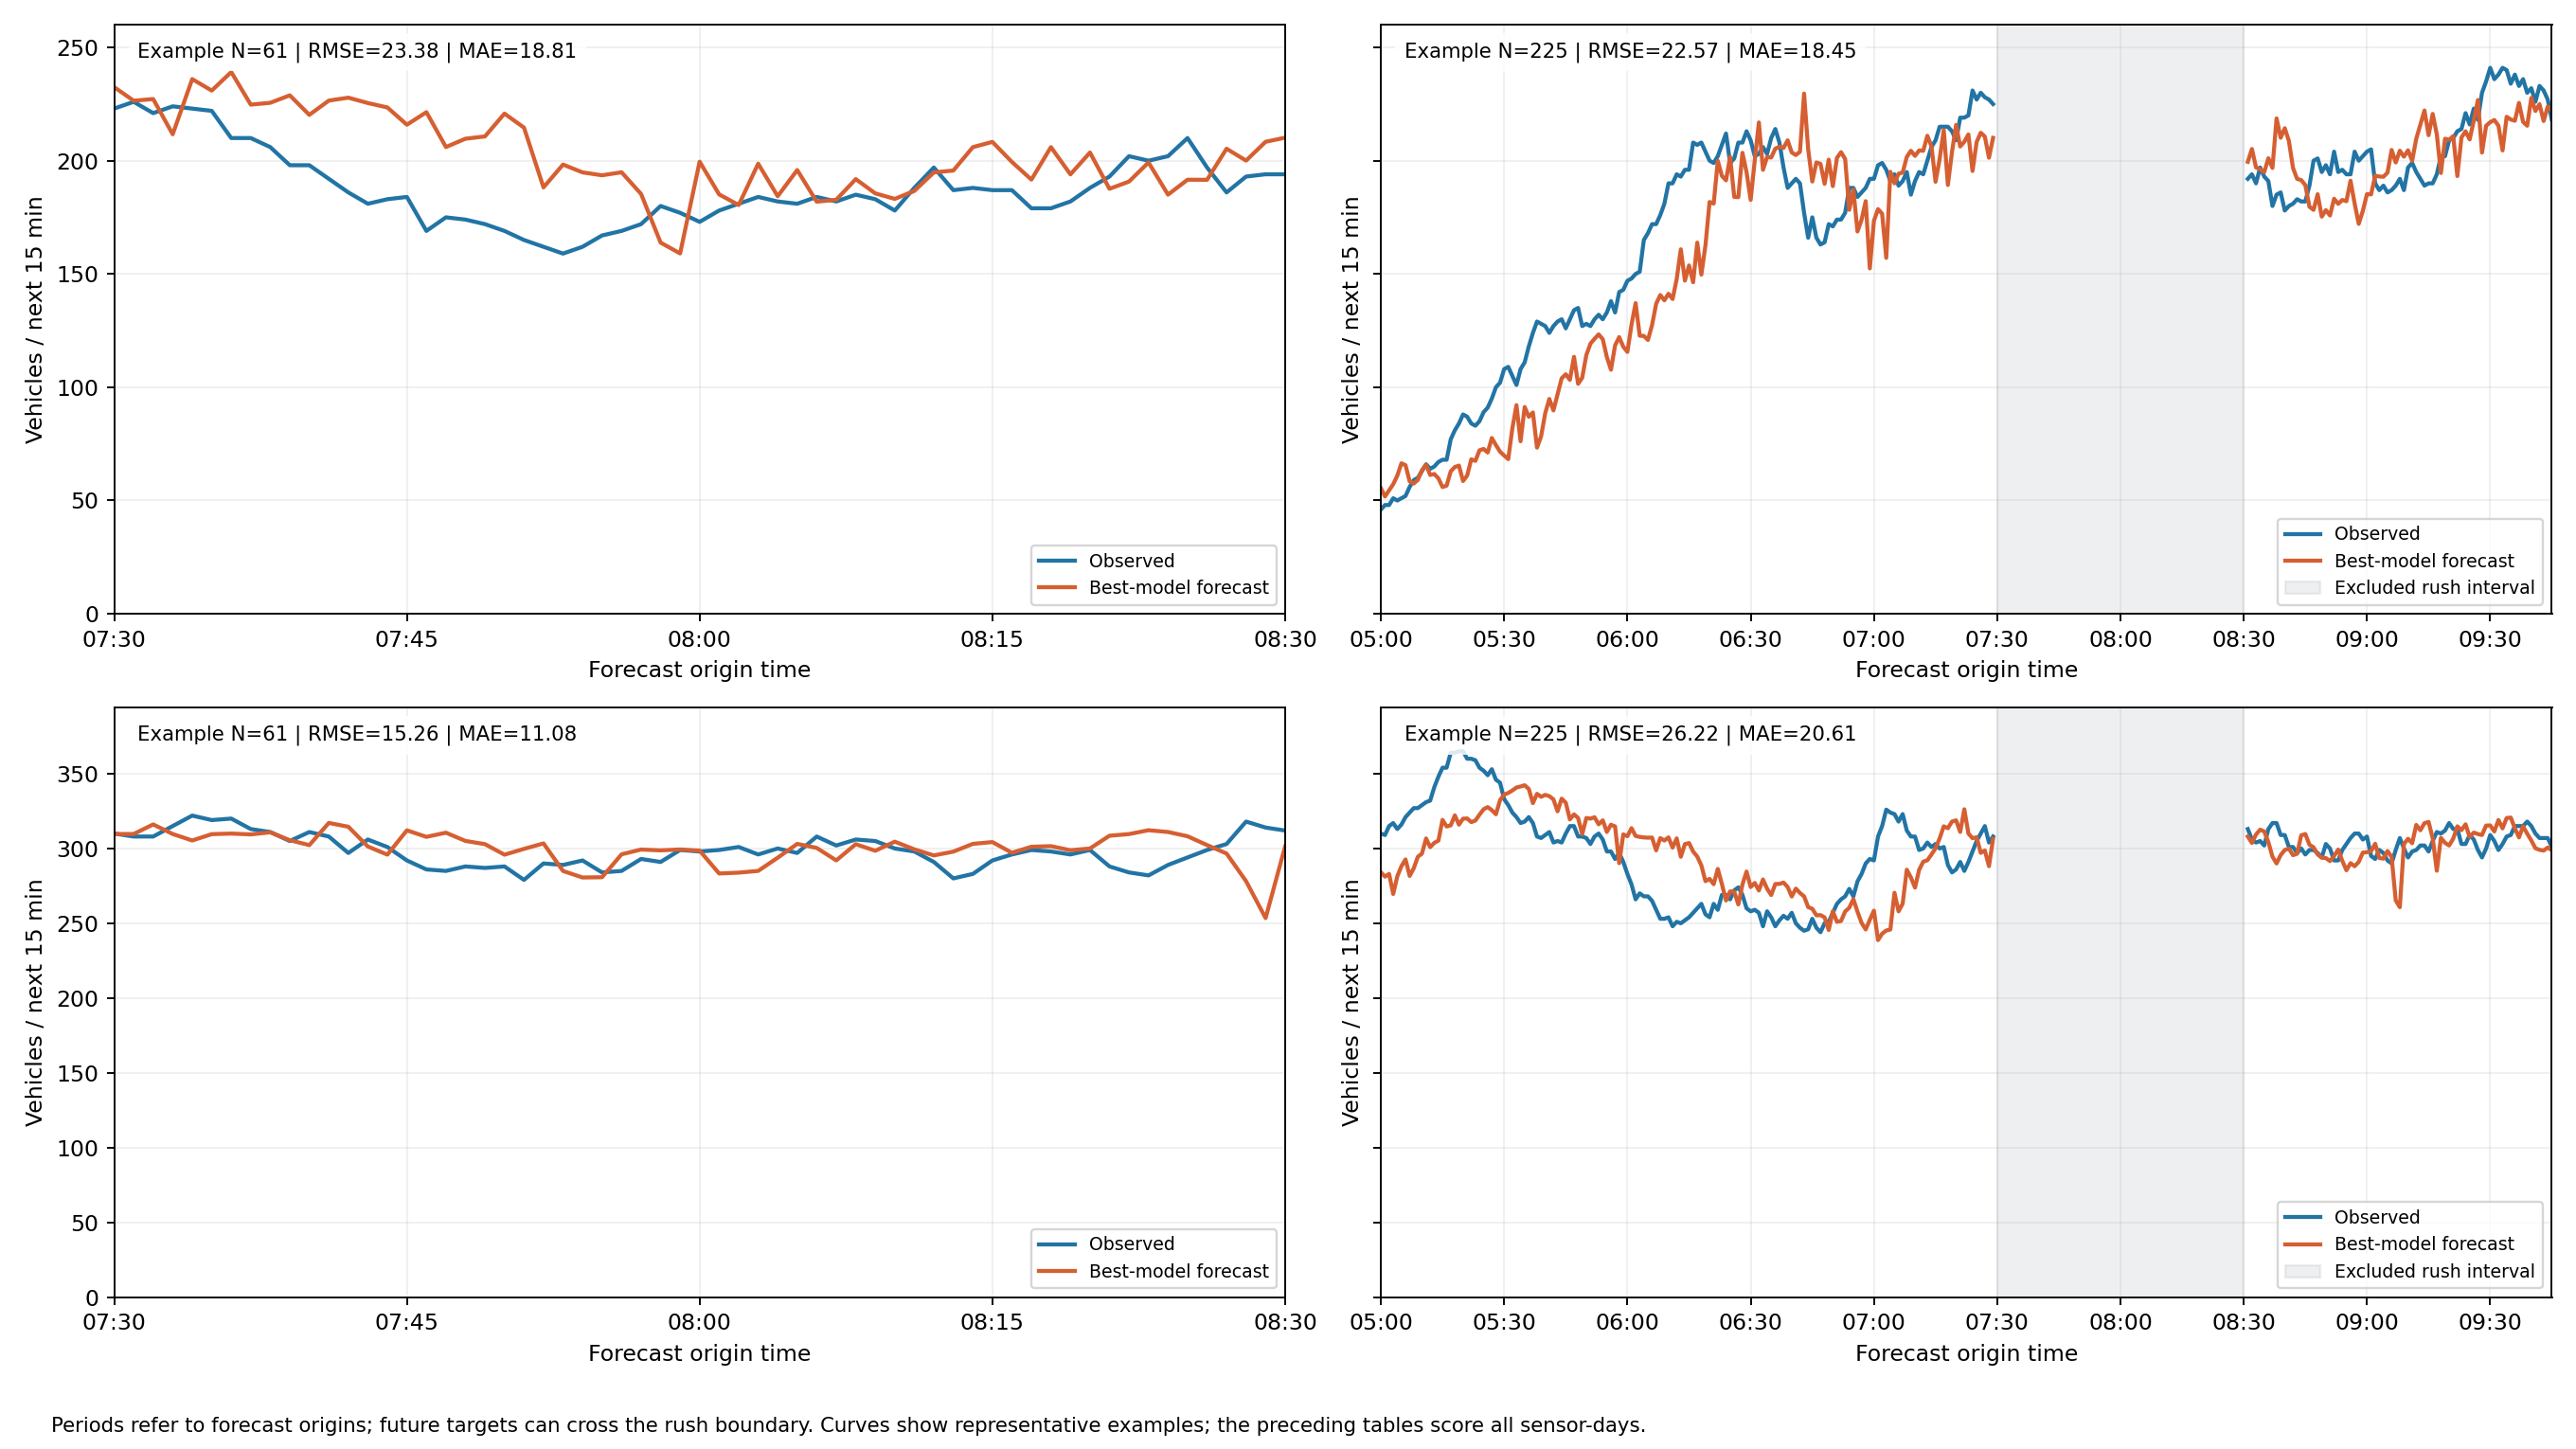

Dataset,Period,Algorithm,Configuration,DP_ID,PORTAL,Date,MAE,RMSE,MAPE_percent,MAPE_excluded_zero_targets,R2,N
Final evaluation dataset,Within rush window,XGBoost,D,4494,"E4S 58,140",2022-04-14,18.812,23.383,10.366,0,-1.020,61
Final evaluation dataset,Outside rush window,XGBoost,D,4494,"E4S 58,140",2022-04-14,18.445,22.571,11.852,0,0.798,225
Evaluation dataset,Within rush window,XGBoost,D,1079,"E4S 56,780",2022-03-30,11.083,15.261,3.736,0,-1.036,61
Evaluation dataset,Outside rush window,XGBoost,D,1079,"E4S 56,780",2022-03-30,20.611,26.224,6.957,0,0.110,225


In [ ]:
# Compare the frozen best model's rolling forecasts with observations within/outside rush hour.
# Uses Section 9.5 predictions: no fitting or model selection takes place here.
import matplotlib.dates as mdates
from IPython.display import Image, display

rush_curve_periods = ['Within rush window', 'Outside rush window']
rush_curve_figure, rush_curve_axes = plt.subplots(
    len(rush_diagnostic_datasets), 2, figsize=(16, 9),
    squeeze=False, sharey='row')
plt.close(rush_curve_figure)
rush_forecast_example_results = []
for row, (label, data) in enumerate(rush_diagnostic_datasets.items()):
    curve_data = data.copy()
    curve_data['date'] = curve_data['timestamp'].dt.normalize()
    # Keep the same matched example as Section 9.4 whenever it is available.
    curve_key = common_example
    if curve_key is None or not (
            curve_data['DP_ID'].eq(curve_key[0]) & curve_data['date'].eq(curve_key[1])).any():
        scorable = curve_data.dropna(subset=['TARGET', 'prediction']).copy()
        scorable['absolute_error'] = (scorable['prediction'] - scorable['TARGET']).abs()
        candidates = scorable.groupby(['DP_ID', 'date']).agg(
            MAE=('absolute_error', 'mean'), Periods=('rush_period', 'nunique'))
        candidates = candidates.loc[candidates['Periods'] == 2]
        if candidates.empty:
            raise ValueError(f'{label}: no sensor-day has observations in both rush periods.')
        curve_key = (candidates['MAE'] - candidates['MAE'].median()).abs().idxmin()
    curve_sensor, curve_date = curve_key
    minute_index = pd.date_range(
        curve_date + pd.Timedelta(minutes=DIAGNOSTIC_START_MINUTE),
        curve_date + pd.Timedelta(minutes=DIAGNOSTIC_END_MINUTE), freq='min')
    curve_example = curve_data.loc[
        curve_data['DP_ID'].eq(curve_sensor) & curve_data['date'].eq(curve_date)]
    curve_portal = curve_example['PORTAL'].iloc[0]
    curve_example = curve_example.set_index('timestamp').reindex(minute_index)
    minute = minute_index.hour * 60 + minute_index.minute
    within = (minute >= RUSH_START_MINUTE) & (minute <= RUSH_END_MINUTE)
    for column, period in enumerate(rush_curve_periods):
        ax = rush_curve_axes[row, column]
        selected = within if column == 0 else ~within
        # Reindexing and masking retain real gaps; do not join the two outside intervals.
        observed = curve_example['TARGET'].where(selected)
        forecast = curve_example['prediction'].where(selected)
        ax.plot(minute_index, observed, color='#2274a5', linewidth=1.8, label='Observed')
        ax.plot(minute_index, forecast, color='#d65f32', linewidth=1.8, label='Best-model forecast')
        paired = pd.DataFrame({'TARGET': observed, 'prediction': forecast}).dropna()
        example_metrics = (calculate_metrics(paired['TARGET'], paired['prediction'])
                           if len(paired) >= 2 else {'N': len(paired), 'MAE': np.nan, 'RMSE': np.nan, 'R2': np.nan})
        rush_forecast_example_results.append({
            'Dataset': label, 'Period': period, 'Algorithm': best_algorithm,
            'Configuration': best_configuration, 'DP_ID': curve_sensor, 'PORTAL': curve_portal,
            'Date': curve_date.strftime('%Y-%m-%d'), **example_metrics})
        ax.text(.02, .97, f"Example N={example_metrics['N']} | RMSE={example_metrics['RMSE']:.2f} | "
                f"MAE={example_metrics['MAE']:.2f}", transform=ax.transAxes, va='top', fontsize=9,
                bbox=dict(facecolor='white', edgecolor='none', alpha=.85))
        rush_start = curve_date + pd.Timedelta(minutes=RUSH_START_MINUTE)
        rush_end = curve_date + pd.Timedelta(minutes=RUSH_END_MINUTE)
        if column == 0:
            ax.set_xlim(rush_start, rush_end)
            ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
        else:
            ax.set_xlim(minute_index[0], minute_index[-1])
            ax.axvspan(rush_start, rush_end, color='#738390', alpha=.12, label='Excluded rush interval')
            ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
        ax.set(xlabel='Forecast origin time', ylabel=TARGET_AXIS_LABEL, ylim=(0, None))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8, loc='lower right')
    # Use both periods to set the range; adding a higher-flow example must not clip curves.
    row_values = curve_example[['TARGET', 'prediction']].to_numpy(dtype=float)
    row_values = row_values[np.isfinite(row_values)]
    row_upper = max(1., row_values.max() * 1.08) if len(row_values) else 1.
    for ax in rush_curve_axes[row]:
        ax.set_ylim(0, row_upper)
# Export a 16:9 canvas without a main title or panel titles.
rush_curve_figure.tight_layout(rect=(0, .04, 1, 1))
rush_curve_figure.text(.02, .012,
    'Periods refer to forecast origins; future targets can cross the rush boundary. '
    'Curves show representative examples; the preceding tables score all sensor-days.', fontsize=9)
rush_forecast_graph_path = OUTPUT_DIR / 'forecast_vs_observed_within_outside_rush.png'
# Tight bounding-box cropping would change the image's aspect ratio.
with plt.rc_context({'savefig.bbox': None}):
    rush_curve_figure.savefig(rush_forecast_graph_path, dpi=170, bbox_inches=None, facecolor='white')
display(Image(filename=str(rush_forecast_graph_path), width=1200))
rush_forecast_example_results = pd.DataFrame(rush_forecast_example_results)
display(rush_forecast_example_results.round(3))
rush_forecast_example_results.to_csv(OUTPUT_DIR / 'rush_forecast_example_metrics.csv', index=False)
print('Saved:', rush_forecast_graph_path)


In [1358]:
# Report the measured difference without claiming a causal rush-hour effect.

for label, summary in rush_comparison.groupby('Dataset', sort=False):
    values = summary.set_index('Period')
    if not {'Within rush window', 'Outside rush window'}.issubset(values.index):
        continue
    inside, outside = values.loc['Within rush window'], values.loc['Outside rush window']
    change = 100 * (outside['RMSE'] / inside['RMSE'] - 1) if inside['RMSE'] else np.nan
    print(f"{label}: within RMSE {inside['RMSE']:.3f}, outside RMSE {outside['RMSE']:.3f} "
          f"{TARGET_UNIT} ({change:+.1f}%); R² {inside['R2']:.3f} → {outside['R2']:.3f}.")
    print(f"  Coverage: {inside['Coverage_percent']:.1f}% within / "
          f"{outside['Coverage_percent']:.1f}% outside. Complete-own-history RMSE: "
          f"{inside['Full_history_RMSE']:.3f} / {outside['Full_history_RMSE']:.3f}.")
    print(f"  RMSE improvement over persistence on matched rows: "
          f"{inside['RMSE_skill_percent']:.1f}% within / {outside['RMSE_skill_percent']:.1f}% outside.")
print('The model was trained only within 07:30–08:30. Period differences are descriptive; '
      'the evaluation files may overlap and missing-target exclusion can affect the comparison.')


Final evaluation dataset: within RMSE 24.508, outside RMSE 29.708 vehicles (+21.2%); R² 0.928 → 0.900.
  Coverage: 77.9% within / 73.0% outside. Complete-own-history RMSE: 24.252 / 28.547.
  RMSE improvement over persistence on matched rows: 58.7% within / 50.6% outside.
Evaluation dataset: within RMSE 27.090, outside RMSE 29.362 vehicles (+8.4%); R² 0.915 → 0.904.
  Coverage: 78.9% within / 72.5% outside. Complete-own-history RMSE: 26.657 / 28.523.
  RMSE improvement over persistence on matched rows: 55.0% within / 50.9% outside.
The model was trained only within 07:30–08:30. Period differences are descriptive; the evaluation files may overlap and missing-target exclusion can affect the comparison.


### 9.6 Speed-average and FLOW correlation: rush versus normal time

This section has two steps: (1) divide observed data into rush/normal time; (2) show the SPEED_MS_AVG–FLOW correlation separately for each period. Use simultaneous observed one-minute measurements, not the model's future window/point target. No prediction model is fitted or changed.


#### 9.6.1 Divide the data into rush and normal time

Weekdays and weekends are included together in this simple comparison.


In [1359]:
# Define the time split and output directory for this observed-data diagnostic.

CORRELATION_RUSH_START = 7 * 60 + 30
CORRELATION_RUSH_END = 8 * 60 + 30
CORRELATION_MAX_SPEED_MS = 60.
SPEED_FLOW_DIR = OUTPUT_DIR / 'speed_flow_correlation'
SPEED_FLOW_DIR.mkdir(parents=True, exist_ok=True)


In [1360]:
# Assign recorded sensor-minute observations to rush or normal time.

def prepare_speed_flow_rows(source_path):
    columns = ['DP_ID', 'Date', 'Time', 'FLOW', 'SPEED_MS_AVG']
    rows = pd.read_csv(source_path, sep=';', usecols=columns)
    rows['timestamp'] = pd.to_datetime(rows['Date'].astype(str) + ' ' + rows['Time'].astype(str), errors='coerce')
    if rows['timestamp'].isna().any():
        raise ValueError(f'Invalid timestamps in {source_path.name}; resolve before splitting periods.')
    if rows.duplicated(['DP_ID', 'timestamp']).any():
        raise ValueError(f'Duplicate sensor-minute records in {source_path.name}.')
    for name in ['FLOW', 'SPEED_MS_AVG']:
        rows[name] = pd.to_numeric(rows[name], errors='coerce')
    minute = rows['timestamp'].dt.hour * 60 + rows['timestamp'].dt.minute
    rows['Period'] = np.where(minute.between(CORRELATION_RUSH_START, CORRELATION_RUSH_END), 'Rush', 'Normal')
    rows['valid_pair'] = (rows['FLOW'].gt(0) & rows['SPEED_MS_AVG'].gt(0) &
                          rows['SPEED_MS_AVG'].le(CORRELATION_MAX_SPEED_MS) &
                          np.isfinite(rows['FLOW']) & np.isfinite(rows['SPEED_MS_AVG']))
    return rows[['timestamp', 'DP_ID', 'FLOW', 'SPEED_MS_AVG', 'Period', 'valid_pair']]


In [1361]:
# Keep each dataset separate and report the number of usable observations.

speed_flow_datasets = {}
speed_flow_split_records = []
for label, source in [('Training dataset', TRAIN_PATH), ('Final evaluation dataset', FINAL_EVAL_PATH),
                       ('Evaluation dataset', EVAL_PATH)]:
    data = prepare_speed_flow_rows(source)
    speed_flow_datasets[label] = data
    for period, part in data.groupby('Period'):
        speed_flow_split_records.append({'Dataset': label, 'Period': period,
            'Recorded_rows': len(part), 'Usable_pairs': int(part['valid_pair'].sum()),
            'Excluded_pairs': int((~part['valid_pair']).sum()),
            'Zero_FLOW': int(part['FLOW'].eq(0).sum()), 'Missing_FLOW': int(part['FLOW'].isna().sum()),
            'Missing_speed': int(part['SPEED_MS_AVG'].isna().sum())})
speed_flow_split_summary = pd.DataFrame(speed_flow_split_records)
display(speed_flow_split_summary)
speed_flow_split_summary.to_csv(SPEED_FLOW_DIR / 'rush_normal_split_summary.csv', index=False)


,Dataset,Period,Recorded_rows,Usable_pairs,Excluded_pairs,Zero_FLOW,Missing_FLOW,Missing_speed
0,Training dataset,Normal,1574310,1574253,57,0,55,0
1,Training dataset,Rush,347657,347650,7,0,7,0
2,Final evaluation dataset,Normal,659202,659190,12,0,2,0
3,Final evaluation dataset,Rush,144299,144297,2,0,2,0
4,Evaluation dataset,Normal,658023,657990,33,0,29,0
5,Evaluation dataset,Rush,145354,145354,0,0,0,0


#### 9.6.2 Show speed-average and FLOW correlation for rush and normal time

Calculate Pearson r for the linear association and Spearman rho for the rank/monotonic association, using every usable FLOW–SPEED_MS_AVG pair in each dataset and period. Neither measure proves congestion or causation, and a nonlinear relationship can have a weak overall correlation. Return NaN for insufficient data or a constant variable.


In [1362]:
# Measure the speed-flow association without fitting a forecasting model.

def speed_flow_metrics(part):
    usable = part.loc[part['valid_pair']]
    variable = (len(usable) >= 3 and usable['FLOW'].nunique() > 1 and
                usable['SPEED_MS_AVG'].nunique() > 1)
    return {'N': len(usable), 'Mean_FLOW': usable['FLOW'].mean(),
            'Mean_speed_ms': usable['SPEED_MS_AVG'].mean(),
            'Pearson_r': usable['FLOW'].corr(usable['SPEED_MS_AVG']) if variable else np.nan,
            'Spearman_rho': usable['FLOW'].corr(usable['SPEED_MS_AVG'], method='spearman') if variable else np.nan}


In [1363]:
# Compare pooled and within-sensor correlations across the two periods.

speed_flow_records, speed_flow_sensor_records = [], []
for label, data in speed_flow_datasets.items():
    for period, part in data.groupby('Period'):
        speed_flow_records.append({'Dataset': label, 'Period': period, **speed_flow_metrics(part)})
    for (sensor, period), part in data.groupby(['DP_ID', 'Period']):
        speed_flow_sensor_records.append({'Dataset': label, 'DP_ID': sensor, 'Period': period,
                                          **speed_flow_metrics(part)})
speed_flow_correlations = pd.DataFrame(speed_flow_records)
speed_flow_sensor_correlations = pd.DataFrame(speed_flow_sensor_records)
display(speed_flow_correlations.round(4))
sensor_comparison = speed_flow_sensor_correlations.pivot(index=['Dataset', 'DP_ID'], columns='Period', values='Pearson_r')
sensor_comparison['Rush_minus_normal'] = sensor_comparison['Rush'] - sensor_comparison['Normal']
display(sensor_comparison.round(4))
speed_flow_correlations.to_csv(SPEED_FLOW_DIR / 'rush_normal_correlations.csv', index=False)
speed_flow_sensor_correlations.to_csv(SPEED_FLOW_DIR / 'sensor_rush_normal_correlations.csv', index=False)
sensor_comparison.to_csv(SPEED_FLOW_DIR / 'sensor_correlation_comparison.csv')


,Dataset,Period,N,Mean_FLOW,Mean_speed_ms,Pearson_r,Spearman_rho
0,Training dataset,Normal,1574253,12.0414,20.1225,-0.2787,-0.2753
1,Training dataset,Rush,347650,13.8331,19.6014,-0.2309,-0.2252
2,Final evaluation dataset,Normal,659190,12.1157,20.1554,-0.2137,-0.2197
3,Final evaluation dataset,Rush,144297,13.8500,19.6544,-0.1805,-0.1929
4,Evaluation dataset,Normal,657990,11.6588,20.1740,-0.2107,-0.2114
5,Evaluation dataset,Rush,145354,13.4569,19.5398,-0.2004,-0.2040


Period                    Normal    Rush  Rush_minus_normal
Dataset            DP_ID                                   
Evaluation dataset 153   -0.4549 -0.4947            -0.0398
                   351   -0.5521 -0.3893             0.1628
                   353   -0.4375 -0.2887             0.1488
                   534   -0.4076 -0.4402            -0.0326
                   536   -0.4684 -0.4908            -0.0224
...                          ...     ...                ...
Training dataset   4494  -0.3553 -0.4692            -0.1138
                   4495  -0.3006 -0.2401             0.0605
                   4496  -0.2005 -0.1090             0.0915
                   4872  -0.2477 -0.2928            -0.0451
                   4873  -0.3736 -0.4561            -0.0824

[87 rows x 3 columns]

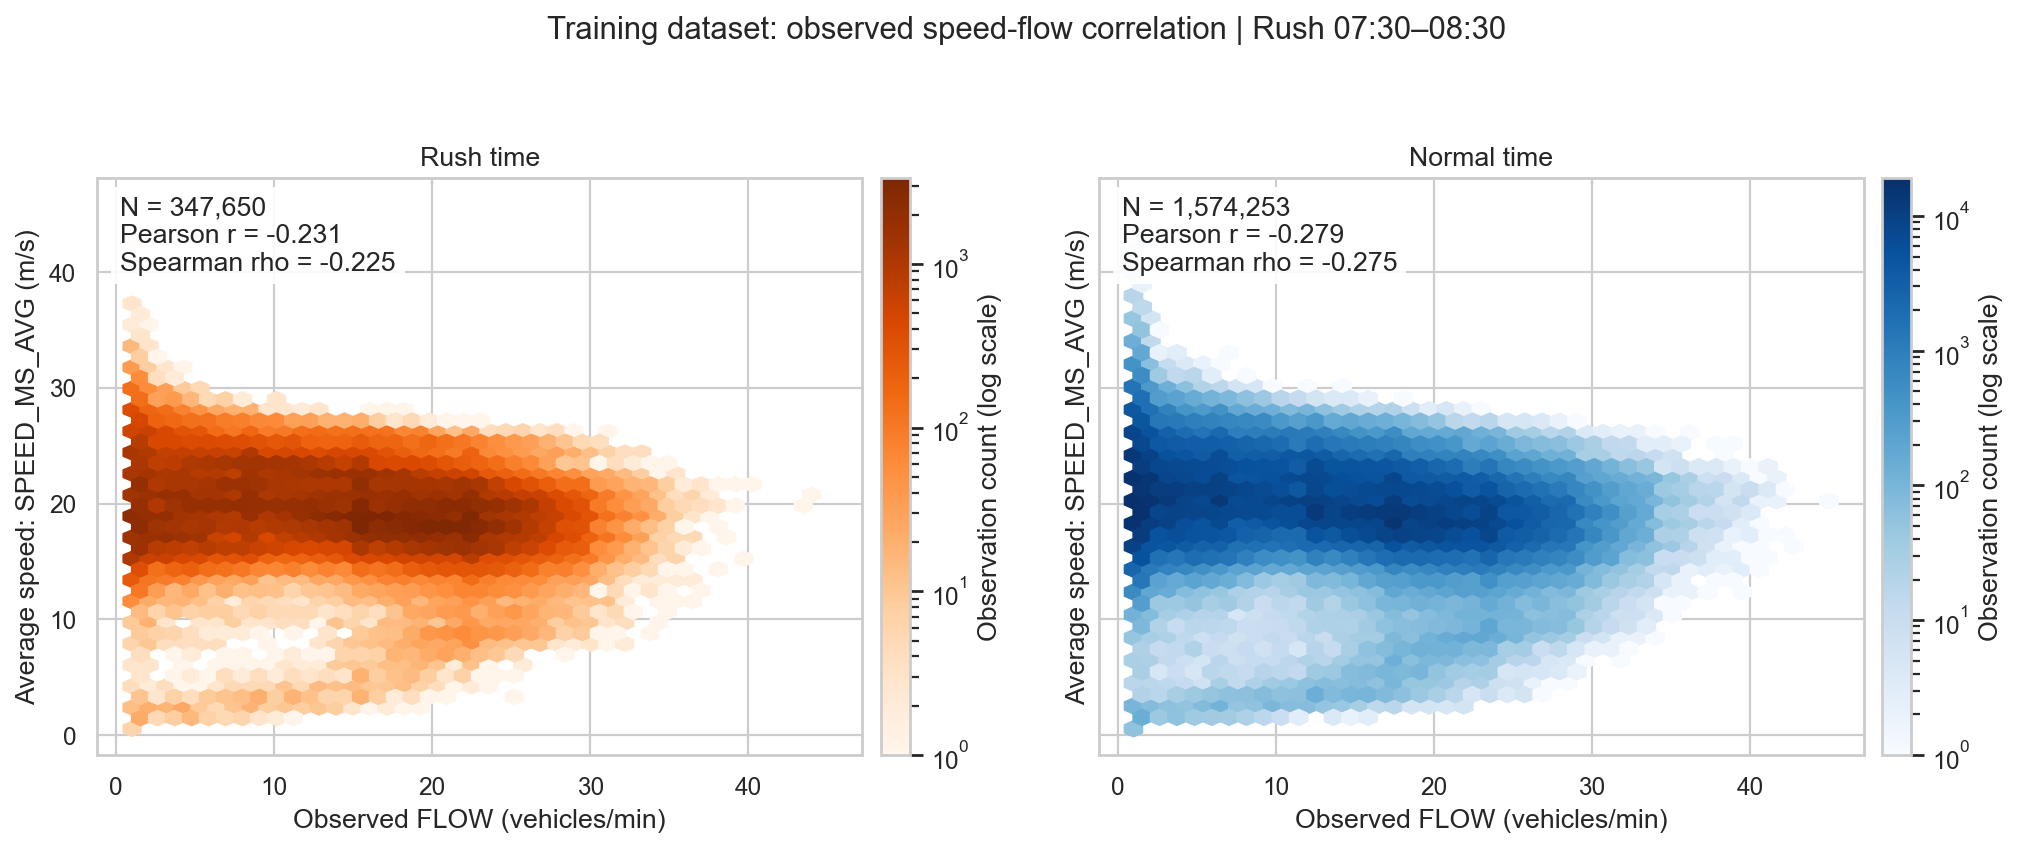

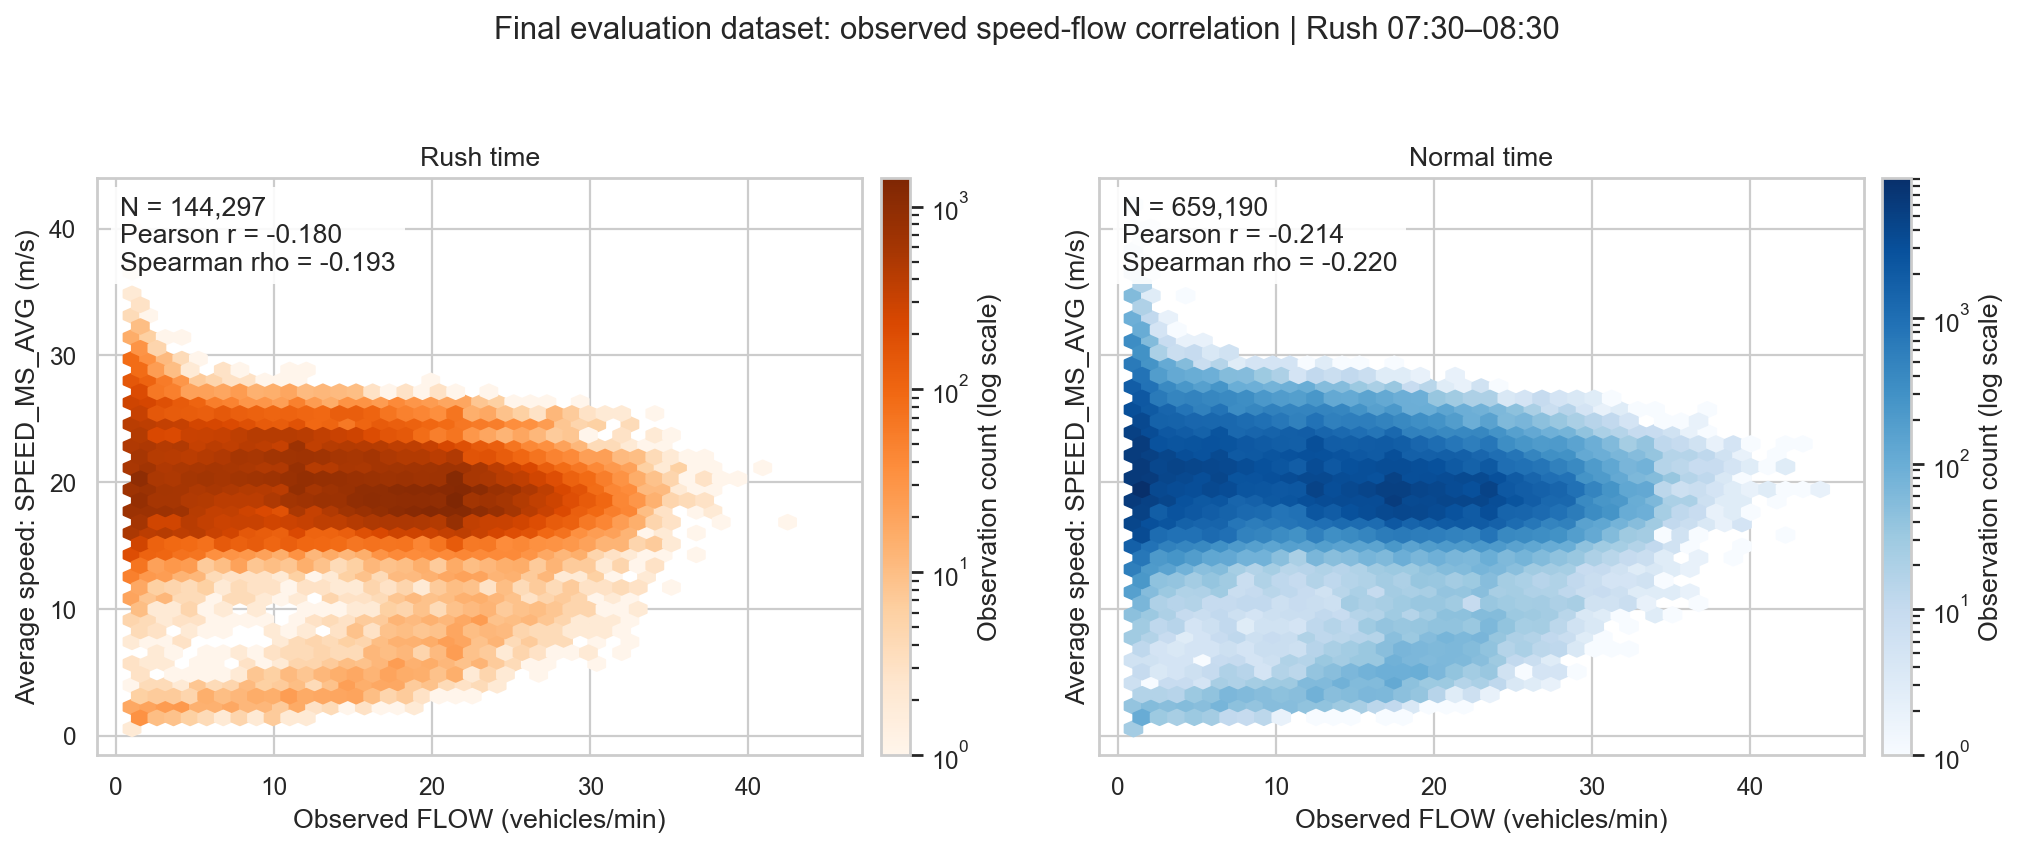

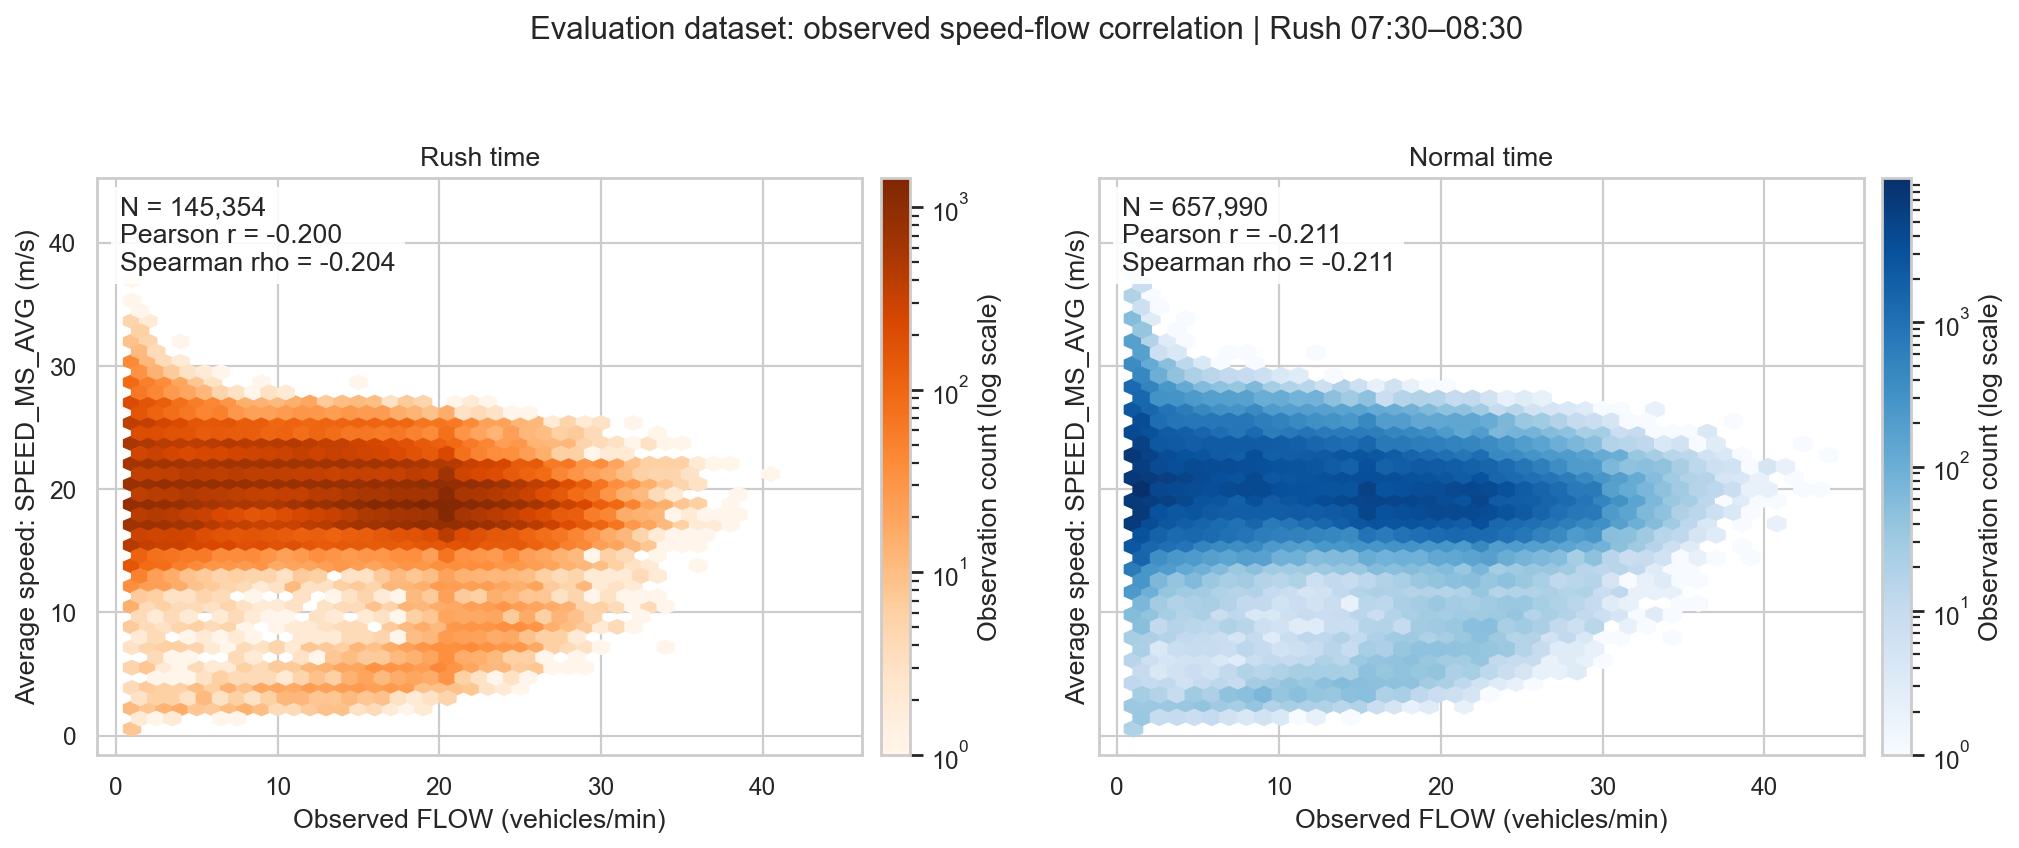

In [1364]:
# Show observed FLOW versus average speed for rush and normal time.

from IPython.display import Image, display

speed_flow_graphs = []
for label, data in speed_flow_datasets.items():
    usable = data.loc[data['valid_pair']]
    figure, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
    plt.close(figure)
    for ax, period, cmap in zip(axes, ['Rush', 'Normal'], ['Oranges', 'Blues']):
        part = usable.loc[usable['Period'] == period]
        metrics = speed_flow_metrics(part)
        if part.empty:
            ax.text(.5, .5, 'No usable observations', transform=ax.transAxes, ha='center')
            continue
        density = ax.hexbin(part['FLOW'], part['SPEED_MS_AVG'], gridsize=40,
                            mincnt=1, bins='log', cmap=cmap)
        figure.colorbar(density, ax=ax, pad=.02).set_label('Observation count (log scale)')
        ax.set(title=f'{period} time', xlabel='Observed FLOW (vehicles/min)',
               ylabel='Average speed: SPEED_MS_AVG (m/s)')
        ax.text(.03, .97, f"N = {metrics['N']:,}\nPearson r = {metrics['Pearson_r']:.3f}\n"
                f"Spearman rho = {metrics['Spearman_rho']:.3f}", transform=ax.transAxes, va='top',
                bbox=dict(facecolor='white', edgecolor='none', alpha=.9))
    figure.suptitle(f'{label}: observed speed-flow correlation | Rush 07:30–08:30', fontsize=14)
    figure.tight_layout(rect=(0, .02, 1, .93))
    name = label.lower().replace(' ', '_')
    graph_path = SPEED_FLOW_DIR / f'speed_flow_rush_normal_{name}.png'
    figure.savefig(graph_path, dpi=160, bbox_inches='tight', facecolor='white')
    display(Image(filename=str(graph_path), width=1100))
    speed_flow_graphs.append(graph_path)


Interpretation: negative Pearson r means higher observed FLOW tends to accompany lower average speed; positive r means they tend to increase together. Values near zero mean a weak linear association, not necessarily no traffic relationship. Spearman rho adds a monotonic-association check. Inspect the plotted shapes and individual-sensor correlations before interpreting pooled values. A difference in correlation alone cannot confirm that low FLOW means queues in rush time or low demand in normal time.


### 9.7 Save results

In [1365]:
# Save metrics and private prediction outputs.

final_results.to_csv(OUTPUT_DIR / 'final_results.csv', index=False)
evaluation_coverage.to_csv(OUTPUT_DIR / 'evaluation_coverage.csv', index=False)
monthly_results.to_csv(OUTPUT_DIR / 'monthly_results.csv', index=False)
final_sensor_results.to_csv(OUTPUT_DIR / 'final_sensor_results.csv', index=False)
final_portal_results.to_csv(OUTPUT_DIR / 'final_portal_results.csv', index=False)
# Predictions are derived from private course data; keep this directory private.
evaluation_all[['timestamp', 'DP_ID', 'PORTAL', 'TARGET', 'prediction']].to_csv(
    OUTPUT_DIR / 'final_predictions_PRIVATE.csv', index=False)

### 9.8 Save and reload the best trained model


In [ ]:
# Save the original fitted pipeline and a native Keras inference model.
from traffic_model_export import save_best_model

feature_columns = configuration_inputs(final_training_sample, best_configuration).columns.tolist()
bundle = {'model': final_model, 'configuration': best_configuration, 'algorithm': best_algorithm,
          'sensor_ids': sensor_ids, 'portal_by_sensor': portal_by_sensor,
          'portal_order': portal_order, 'horizon': HORIZON, 'parameters': best_parameters,
          'target_mode': TARGET_MODE, 'target_unit': TARGET_UNIT,
          'target_aggregation': TARGET_AGGREGATION if TARGET_MODE == 'window' else None,
          'feature_version': FEATURE_VERSION, 'historical_flow_lags': FLOW_LAGS,
          'feature_columns': feature_columns}
joblib_path = OUTPUT_DIR / 'best_model.joblib'
joblib.dump(bundle, joblib_path)
loaded = joblib.load(joblib_path)
check_inputs = configuration_inputs(final_training_sample.head(1000), best_configuration)
np.testing.assert_allclose(predict_flow(final_model, check_inputs),
                           predict_flow(loaded['model'], check_inputs))

model_path = OUTPUT_DIR / 'best_model.keras'
keras_model = save_best_model(final_model, model_path, check_inputs)
print('Saved and reload-verified:', model_path)


In [ ]:
# Record the selected parameters and training assumptions.

metadata = {'algorithm': best_algorithm, 'configuration': best_configuration,
            'model_file': model_path.name, 'original_pipeline_file': joblib_path.name,
            'model_format': 'native Keras 3 inference graph of the fitted XGBoost pipeline',
            'feature_columns': feature_columns, 'input_dtype': 'float64',
            'output_shape': '(n_rows, 1)',
            'reload_verification_rtol': 1e-5, 'reload_verification_atol': 1e-4,
            'configuration_description': configuration_names[best_configuration],
            'parameters': best_parameters, 'horizon_minutes': HORIZON,
            'target': TARGET_SPECIFICATION,
            'target_mode': TARGET_MODE, 'target_unit': TARGET_UNIT,
            'target_aggregation': TARGET_AGGREGATION if TARGET_MODE == 'window' else None,
            'feature_version': FEATURE_VERSION, 'historical_flow_lags': FLOW_LAGS,
            'training_rows_used': len(final_training_sample),
            'training_rows_eligible': len(development_data),
            'portal_order': portal_order, 'random_state': RANDOM_STATE,
            'MAPE_policy': 'exclude zero targets; report excluded count',
            'evaluation_filename': FINAL_EVAL_PATH.name,
            'cv_splits': N_CV_SPLITS, 'search_iterations': SEARCH_ITERATIONS,
            'cv_train_limit': MAX_CV_TRAIN_ROWS, 'cv_score_limit': MAX_CV_VALIDATION_ROWS,
            'selection_method': 'joint configuration/parameter CV per algorithm; held-out validation winner',
            '2022_benchmark_reused': True}
(OUTPUT_DIR / 'best_model_metadata.json').write_text(json.dumps(metadata, indent=2))
print('Saved and reload-verified:', model_path)
print('Outputs:', OUTPUT_DIR)